In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/annurtasnia/cse475project/grasps_en.PNG
/kaggle/input/datasets/annurtasnia/cse475project/Database 1/female_1.mat
/kaggle/input/datasets/annurtasnia/cse475project/Database 1/female_2.mat
/kaggle/input/datasets/annurtasnia/cse475project/Database 1/female_3.mat
/kaggle/input/datasets/annurtasnia/cse475project/Database 1/male_1.mat
/kaggle/input/datasets/annurtasnia/cse475project/Database 1/male_2.mat
/kaggle/input/datasets/annurtasnia/cse475project/Database 2/male_day_1.mat
/kaggle/input/datasets/annurtasnia/cse475project/Database 2/male_day_2.mat
/kaggle/input/datasets/annurtasnia/cse475project/Database 2/male_day_3.mat


In [2]:
# =========== imports + configuration ============
import os, time, copy, glob, zipfile, warnings, random
import numpy as np, pandas as pd, scipy.io as sio
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, cohen_kappa_score, roc_auc_score,
                             confusion_matrix, classification_report)
import torch, torch.nn as nn, torch.nn.functional as F
try:
    import xgboost as xgb
except ImportError:
    xgb = None            # Colab: !pip install xgboost
try:
    import lightgbm as lgb
except ImportError:
    lgb = None            # Colab: !pip install lightgbm
warnings.filterwarnings("ignore")

# ---------------- configuration ----------------
SEED      = 42
DATA_ZIP  = os.environ.get("SEMG_ZIP", "semgforbasichandmovements.zip")   # Colab: upload the zip next to the notebook
DATA_DIR  = "semg_data"
DATASET   = "DB1"      # "DB1": 5 subjects  -> Leave-One-Subject-Out
                       # "DB2": 1 subject, 3 days -> Leave-One-Day-Out
FS        = 500        # sampling rate (Hz), only used for spectral features
WIN, STEP = 250, 125   # window / hop (samples)
K_SEG     = 5          # sub-segments per window (= temporal nodes per channel in the GNN)
CAL_FRAC  = 0.2        # fraction of held-out subject's TRIALS used as calibration (X_Cal); rest = X_Test
PCA_VAR   = 0.95       # PCA keeps 95% variance (as in the pipeline figure)
K_BEST    = 16         # univariate feature selection (inside the pipeline, train-only). None = skip
TUNE      = False      # True -> inner GroupKFold grid search on TRAINING subjects only (slower)
N_CLS     = 6
CLASSES      = ["cyl", "tip", "hook", "palm", "spher", "lat"]
CLASS_NAMES  = ["Cylindrical", "Tip", "Hook", "Palmar", "Spherical", "Lateral"]
assert WIN % K_SEG == 0

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count() or 1)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV, "| xgboost:", xgb is not None, "| lightgbm:", lgb is not None)

device: cuda | xgboost: True | lightgbm: True


In [3]:
# ============  load data (works on Kaggle / Colab / local) ============
# Kaggle: add the dataset via "+ Add Input" (zip or extracted folder both work). Colab/local: put the zip next to the notebook.
db_folder = "Database 1" if DATASET == "DB1" else "Database 2"

def find_db_dir():
    roots = ["/kaggle/input", "/kaggle/working", "/content", ".", DATA_DIR]
    for r in roots:                                              # 1) already-extracted folder
        for dp, dn, fn in os.walk(r):
            if db_folder in dn: return os.path.join(dp, db_folder)
    zips = [DATA_ZIP] if os.path.isfile(DATA_ZIP) else []
    for r in roots:                                              # 2) a zip somewhere -> extract it
        zips += glob.glob(os.path.join(r, "**", "*.zip"), recursive=True)
    for z in zips:
        with zipfile.ZipFile(z) as zf:
            if any(db_folder in n for n in zf.namelist()):
                zf.extractall(DATA_DIR); return find_db_dir()
    raise FileNotFoundError("sEMG data not found - add the dataset as input (Kaggle) or upload the zip")

db_dir = find_db_dir(); print("data folder:", db_dir)
files = sorted(glob.glob(os.path.join(db_dir, "*.mat")))
assert len(files) > 0, "no .mat files found"

def load_group(path):
    m = sio.loadmat(path)
    # (6 classes, n_trials, 2 channels, T)
    X = np.stack([np.stack([m[f"{c}_ch1"], m[f"{c}_ch2"]], axis=1) for c in CLASSES], axis=0)
    n = X.shape[1]
    X = X.reshape(-1, 2, X.shape[-1]).astype(np.float32)
    y = np.repeat(np.arange(N_CLS), n)
    return X, y

RAW = {os.path.splitext(os.path.basename(f))[0]: load_group(f) for f in files}
GROUPS = sorted(RAW.keys())                    # subjects (DB1) or days (DB2)
for g in GROUPS:
    print(f"{g:12s} trials={RAW[g][0].shape[0]:4d}  samples/trial={RAW[g][0].shape[-1]}")

data folder: /kaggle/input/datasets/annurtasnia/cse475project/Database 1
female_1     trials= 180  samples/trial=3000
female_2     trials= 180  samples/trial=3000
female_3     trials= 180  samples/trial=3000
male_1       trials= 180  samples/trial=3000
male_2       trials= 180  samples/trial=3000


In [4]:
# ============  load data (Kaggle path set) ============
import re
DATA_PATH = "/kaggle/input/datasets/annurtasnia/cse475project"

def find_mat_files(root):
    mats = glob.glob(os.path.join(root, "**", "*.mat"), recursive=True)
    if not mats:
        for z in glob.glob(os.path.join(root, "**", "*.zip"), recursive=True):
            with zipfile.ZipFile(z) as zf: zf.extractall(DATA_DIR)
        mats = glob.glob(os.path.join(DATA_DIR, "**", "*.mat"), recursive=True)
    return mats

all_mats = find_mat_files(DATA_PATH)
print("found .mat files:", len(all_mats))
assert len(all_mats) > 0, f"no .mat files under {DATA_PATH}"

pat = re.compile(r"^(male|female)_\d+\.mat$") if DATASET == "DB1" else re.compile(r"^male_day_\d+\.mat$")
files = sorted(f for f in all_mats if pat.match(os.path.basename(f)))
assert len(files) > 0, "no files matching " + DATASET + "; found: " + str([os.path.basename(f) for f in all_mats][:10])

def load_group(path):
    m = sio.loadmat(path)
    X = np.stack([np.stack([m[f"{c}_ch1"], m[f"{c}_ch2"]], axis=1) for c in CLASSES], axis=0)   # (6, n_trials, 2, T)
    n = X.shape[1]
    X = X.reshape(-1, 2, X.shape[-1]).astype(np.float32)
    y = np.repeat(np.arange(N_CLS), n)
    return X, y

RAW = {os.path.splitext(os.path.basename(f))[0]: load_group(f) for f in files}
GROUPS = sorted(RAW.keys())
for g in GROUPS:
    print(f"{g:12s} trials={RAW[g][0].shape[0]:4d}  samples/trial={RAW[g][0].shape[-1]}")

found .mat files: 8
female_1     trials= 180  samples/trial=3000
female_2     trials= 180  samples/trial=3000
female_3     trials= 180  samples/trial=3000
male_1       trials= 180  samples/trial=3000
male_2       trials= 180  samples/trial=3000


,group,n_trials,nan,inf,min_class,max_class,rms_ch1,rms_ch2
0,female_1,180,0,0,30,30,0.701811,0.293202
1,female_2,180,0,0,30,30,0.818828,0.687201
2,female_3,180,0,0,30,30,0.417777,0.477315
3,male_1,180,0,0,30,30,0.293930,0.500382
4,male_2,180,0,0,30,30,0.367740,0.511110


Class imbalance ratio (max/min) = 1.0 -> balanced dataset, no resampling needed; class_weight='balanced' is still used as a safeguard.
RMS differs between subjects -> we normalise PER SUBJECT (Z-norm).


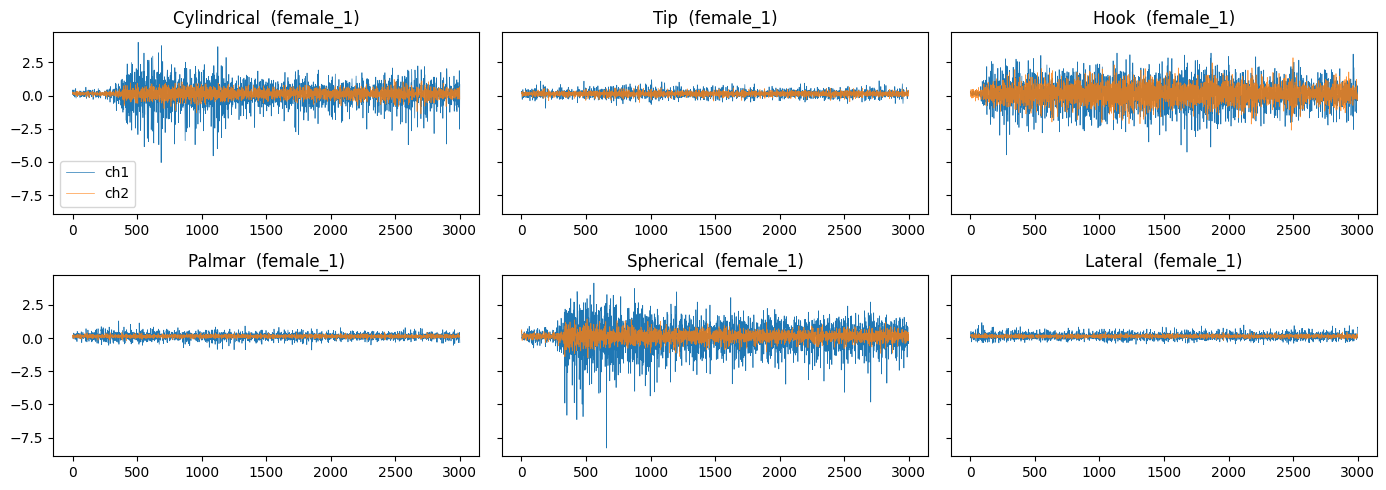

In [5]:
# ============  data sanity ============
rows = []
for g in GROUPS:
    X, y = RAW[g]
    rows.append(dict(group=g, n_trials=len(y), nan=int(np.isnan(X).sum()), inf=int(np.isinf(X).sum()),
                     min_class=int(np.bincount(y).min()), max_class=int(np.bincount(y).max()),
                     rms_ch1=float(np.sqrt((X[:, 0] ** 2).mean())), rms_ch2=float(np.sqrt((X[:, 1] ** 2).mean()))))
sanity = pd.DataFrame(rows); display(sanity)
print("Class imbalance ratio (max/min) =", sanity.max_class.max() / sanity.min_class.min(),
      "-> balanced dataset, no resampling needed; class_weight='balanced' is still used as a safeguard.")
print("RMS differs between subjects -> we normalise PER SUBJECT (Z-norm).")

g0 = GROUPS[0]; X0, y0 = RAW[g0]
fig, axes = plt.subplots(2, 3, figsize=(14, 5), sharey=True)
for c, ax in enumerate(axes.ravel()):
    i = np.where(y0 == c)[0][0]
    ax.plot(X0[i, 0], lw=.5, label="ch1"); ax.plot(X0[i, 1], lw=.5, label="ch2", alpha=.8)
    ax.set_title(f"{CLASS_NAMES[c]}  ({g0})")
axes[0, 0].legend(); plt.tight_layout(); plt.show()

In [6]:
# ============ windowing + feature extraction ============
def make_windows(X):
    starts = np.arange(0, X.shape[-1] - WIN + 1, STEP)
    return np.stack([X[:, :, s:s + WIN] for s in starts], axis=1)

EPS = 1e-8
def td_feats(x):
    d   = np.diff(x, axis=-1)
    thr = 0.1 * x.std(-1, keepdims=True) + EPS
    mav = np.abs(x).mean(-1); rms = np.sqrt((x ** 2).mean(-1)); wl = np.abs(d).sum(-1); var = x.var(-1)
    zc   = ((x[..., :-1] * x[..., 1:] < 0) & (np.abs(d) >= thr)).sum(-1)
    ssc  = (((x[..., 1:-1] - x[..., :-2]) * (x[..., 1:-1] - x[..., 2:])) >= thr ** 2).sum(-1)
    wamp = (np.abs(d) >= thr).sum(-1)
    return np.stack([np.log(mav + EPS), np.log(rms + EPS), np.log(wl + EPS), np.log(var + EPS), zc, ssc, wamp], -1)
TD_NAMES = ["logMAV", "logRMS", "logWL", "logVAR", "ZC", "SSC", "WAMP"]
SP_NAMES = ["MNF", "MDF", "PKF"]

def spec_feats(x):
    P = np.abs(np.fft.rfft(x, axis=-1)) ** 2
    f = np.fft.rfftfreq(x.shape[-1], 1.0 / FS)
    cs = np.cumsum(P, -1)
    mnf = (P * f).sum(-1) / (P.sum(-1) + EPS)
    mdf = f[(cs >= cs[..., -1:] / 2).argmax(-1)]
    pkf = f[P.argmax(-1)]
    return np.stack([mnf, mdf, pkf], -1)

def tab_features(W):
    td, sp = td_feats(W), spec_feats(W)
    a, b = W[:, 0], W[:, 1]
    corr = (a * b).sum(-1) / (np.sqrt((a ** 2).sum(-1) * (b ** 2).sum(-1)) + EPS)
    lratio = td[:, 0, 1] - td[:, 1, 1]
    return np.concatenate([td.reshape(len(W), -1), sp.reshape(len(W), -1), corr[:, None], lratio[:, None]], 1)
TAB_NAMES = [f"ch{c+1}_{n}" for c in range(2) for n in TD_NAMES] + [f"ch{c+1}_{n}" for c in range(2) for n in SP_NAMES] + ["corr12", "logRMS_ratio"]

def graph_inputs(W):
    L = WIN // K_SEG
    seg = W.reshape(len(W), 2, K_SEG, L)
    G = td_feats(seg)
    a = seg[:, 0] - seg[:, 0].mean(-1, keepdims=True); b = seg[:, 1] - seg[:, 1].mean(-1, keepdims=True)
    E = np.abs((a * b).sum(-1) / (np.sqrt((a ** 2).sum(-1) * (b ** 2).sum(-1)) + EPS))
    return G, E

Ws, ys, gs, ts, t_base = [], [], [], [], 0
for g in GROUPS:
    X, y = RAW[g]; w = make_windows(X)
    n, nw = w.shape[:2]
    Ws.append(w.reshape(-1, 2, WIN)); ys.append(np.repeat(y, nw)); gs.append(np.full(n * nw, g))
    ts.append(np.repeat(np.arange(n) + t_base, nw)); t_base += n
W_all = np.concatenate(Ws).astype(np.float64); W_all -= W_all.mean(-1, keepdims=True)
del Ws

G_all, E_all = graph_inputs(W_all)
D = dict(W=W_all.astype(np.float32), F=tab_features(W_all), G=G_all, E=E_all.astype(np.float32),
         y=np.concatenate(ys), grp=np.concatenate(gs), trial=np.concatenate(ts))
TRIALS = pd.DataFrame(dict(trial=D["trial"], grp=D["grp"], y=D["y"])).drop_duplicates("trial").reset_index(drop=True)
F_NODE = D["G"].shape[-1]
print("windows:", len(D["y"]), "| tabular features:", D["F"].shape[1], "| node tensor:", D["G"].shape, "| edge weights:", D["E"].shape)

windows: 20700 | tabular features: 22 | node tensor: (20700, 2, 5, 7) | edge weights: (20700, 5)


In [7]:
# ============ LOSO folds + calibration/test split + per-subject Z-norm + leakage guards ============
def make_fold(test_g, k):
    rng = np.random.RandomState(SEED + k)
    tr_groups = [g for g in GROUPS if g != test_g]
    val_g = tr_groups[k % len(tr_groups)]
    te_mask = D["grp"] == test_g
    cal_trials = []
    for c in range(N_CLS):
        t = TRIALS[(TRIALS.grp == test_g) & (TRIALS.y == c)].trial.values.copy(); rng.shuffle(t)
        cal_trials += list(t[:max(1, int(round(CAL_FRAC * len(t))))])
    is_cal = np.isin(D["trial"], cal_trials)
    f = dict(k=k, test_g=test_g, tr_groups=tr_groups, val_g=val_g,
             idx_tr=np.where(~te_mask)[0], idx_cal=np.where(te_mask & is_cal)[0], idx_te=np.where(te_mask & ~is_cal)[0])
    assert set(D["grp"][f["idx_tr"]]).isdisjoint(set(D["grp"][f["idx_te"]])),  "subject overlap train/test!"
    assert set(D["grp"][f["idx_tr"]]).isdisjoint(set(D["grp"][f["idx_cal"]])), "subject overlap train/cal!"
    assert set(D["trial"][f["idx_cal"]]).isdisjoint(set(D["trial"][f["idx_te"]])), "trial overlap cal/test!"
    assert len(f["idx_tr"]) + len(f["idx_cal"]) + len(f["idx_te"]) == len(D["y"])
    assert val_g in tr_groups and val_g != test_g
    return f

FOLDS = [make_fold(g, k) for k, g in enumerate(GROUPS)]
for f in FOLDS:
    print(f"fold {f['k']}: test={f['test_g']:10s} | train={len(f['idx_tr']):6d} win | cal={len(f['idx_cal']):5d} | test={len(f['idx_te']):5d} | val-subject={f['val_g']}")

def znorm_by_group(arr, fold, axes):
    out = np.empty(arr.shape, dtype=np.float64 if arr.dtype == np.float64 else np.float32)
    for g in GROUPS:
        gi  = np.where(D["grp"] == g)[0]
        ref = fold["idx_cal"] if g == fold["test_g"] else gi      # test subject: stats from calibration windows only
        mu  = arr[ref].mean(axis=axes, keepdims=True); sd = arr[ref].std(axis=axes, keepdims=True) + 1e-8
        out[gi] = (arr[gi] - mu) / sd
    return out

Z_TAB = [znorm_by_group(D["F"], f, axes=(0,)) for f in FOLDS]

def make_prep():
    steps = [("imp", SimpleImputer(strategy="median")), ("vt", VarianceThreshold(1e-8))]
    if K_BEST: steps.append(("kbest", SelectKBest(f_classif, k=K_BEST)))
    steps += [("scale", MinMaxScaler()), ("pca", PCA(n_components=PCA_VAR, svd_solver="full", random_state=SEED))]
    return steps

p = Pipeline(make_prep()).fit(Z_TAB[0][FOLDS[0]["idx_tr"]], D["y"][FOLDS[0]["idx_tr"]])
print("\nfold-0 pipeline: %d raw features -> %d after selection -> %d PCA components (%.1f%% var)" %
      (D["F"].shape[1], p.named_steps["scale"].n_features_in_, p.named_steps["pca"].n_components_, 100 * p.named_steps["pca"].explained_variance_ratio_.sum()))

fold 0: test=female_1   | train= 16560 win | cal=  828 | test= 3312 | val-subject=female_2
fold 1: test=female_2   | train= 16560 win | cal=  828 | test= 3312 | val-subject=female_3
fold 2: test=female_3   | train= 16560 win | cal=  828 | test= 3312 | val-subject=male_1
fold 3: test=male_1     | train= 16560 win | cal=  828 | test= 3312 | val-subject=male_2
fold 4: test=male_2     | train= 16560 win | cal=  828 | test= 3312 | val-subject=female_1

fold-0 pipeline: 22 raw features -> 16 after selection -> 5 PCA components (95.2% var)


In [8]:
# =========== metrics + experiment runners ============
def macro_ovr_auc(y, S):
    aucs = []
    for c in range(N_CLS):
        yy = (y == c).astype(int)
        if 0 < yy.sum() < len(yy): aucs.append(roc_auc_score(yy, S[:, c]))
    return float(np.mean(aucs))

def full_metrics(y, p, S=None):
    return dict(acc=accuracy_score(y, p), bal_acc=balanced_accuracy_score(y, p),
                prec_macro=precision_score(y, p, average="macro", zero_division=0),
                rec_macro=recall_score(y, p, average="macro", zero_division=0),
                f1_macro=f1_score(y, p, average="macro"), f1_weighted=f1_score(y, p, average="weighted"),
                mcc=matthews_corrcoef(y, p), kappa=cohen_kappa_score(y, p),
                auc_ovr=macro_ovr_auc(y, S) if S is not None else np.nan)

ROWS, PRED = [], {}
def reset(name):
    ROWS[:] = [r for r in ROWS if r["model"] != name]; PRED.pop(name, None)

def record(name, fold, y_te, p_te, S_te, y_trs, p_trs, t_fit, t_pred, epochs=np.nan):
    m = full_metrics(y_te, p_te, S_te)
    m.update(model=name, test_group=fold["test_g"], train_f1=f1_score(y_trs, p_trs, average="macro"),
             fit_s=t_fit, pred_s=t_pred, epochs=epochs)
    ROWS.append(m); d = PRED.setdefault(name, dict(y=[], p=[])); d["y"].append(y_te); d["p"].append(p_te)
    print(f"  [{name:18s}] test={fold['test_g']:10s} acc={m['acc']:.3f} f1={m['f1_macro']:.3f} | train_f1={m['train_f1']:.3f} | fit={t_fit:6.1f}s")

def get_scores(model, X):
    if hasattr(model, "predict_proba"): return model.predict_proba(X)
    return model.decision_function(X)

def run_sklearn(name, make_clf, grid=None):
    reset(name); y = D["y"]
    for k, fold in enumerate(FOLDS):
        Z, tr, te = Z_TAB[k], fold["idx_tr"], fold["idx_te"]
        pipe = Pipeline(make_prep() + [("clf", make_clf())])
        t0 = time.time()
        if TUNE and grid:
            gs = GridSearchCV(pipe, grid, cv=GroupKFold(n_splits=len(fold["tr_groups"])), scoring="f1_macro", n_jobs=1)
            gs.fit(Z[tr], y[tr], groups=D["grp"][tr]); pipe = gs.best_estimator_
        else:
            pipe.fit(Z[tr], y[tr])
        t_fit = time.time() - t0
        t0 = time.time(); p = pipe.predict(Z[te]); S = get_scores(pipe, Z[te]); t_pred = time.time() - t0
        trs = np.random.RandomState(SEED).choice(tr, min(4000, len(tr)), replace=False)
        record(name, fold, y[te], p, S, y[trs], pipe.predict(Z[trs]), t_fit, t_pred)

MODELS = {
 "LogReg":       (lambda: LogisticRegression(C=1.0, max_iter=3000, class_weight="balanced"), {"clf__C": [0.1, 1, 10]}),
 "SVM-RBF":      (lambda: SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced"),   {"clf__C": [0.5, 1, 4]}),
 "kNN":          (lambda: KNeighborsClassifier(n_neighbors=25, n_jobs=-1),                    {"clf__n_neighbors": [15, 25, 51]}),
 "DecisionTree": (lambda: DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=SEED), {"clf__max_depth": [4, 8, 12]}),
 "RandomForest": (lambda: RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED), {"clf__max_depth": [8, 12, 16]}),
 "GradBoost":    (lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4, l2_regularization=1.0, early_stopping=False, random_state=SEED), {"clf__max_depth": [3, 4, 6]}),
}
if xgb is not None:
    MODELS["XGBoost"] = (lambda: xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                                   reg_lambda=5.0, tree_method="hist", n_jobs=-1, random_state=SEED, verbosity=0), {"clf__max_depth": [3, 4, 6]})
if lgb is not None:
    MODELS["LightGBM"] = (lambda: lgb.LGBMClassifier(n_estimators=300, num_leaves=15, learning_rate=0.05, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                                     reg_lambda=5.0, min_child_samples=40, n_jobs=-1, random_state=SEED, verbose=-1), {"clf__num_leaves": [7, 15, 31]})
print("baselines:", list(MODELS))

baselines: ['LogReg', 'SVM-RBF', 'kNN', 'DecisionTree', 'RandomForest', 'GradBoost', 'XGBoost', 'LightGBM']


In [9]:
# ===========run classical baselines (LOSO) ============
for name, (mk, grid) in MODELS.items():
    print(name); run_sklearn(name, mk, grid)

LogReg
  [LogReg            ] test=female_1   acc=0.308 f1=0.260 | train_f1=0.576 | fit=   0.3s
  [LogReg            ] test=female_2   acc=0.339 f1=0.313 | train_f1=0.616 | fit=   0.3s
  [LogReg            ] test=female_3   acc=0.506 f1=0.509 | train_f1=0.550 | fit=   0.3s
  [LogReg            ] test=male_1     acc=0.213 f1=0.179 | train_f1=0.597 | fit=   0.3s
  [LogReg            ] test=male_2     acc=0.239 f1=0.258 | train_f1=0.589 | fit=   0.3s
SVM-RBF
  [SVM-RBF           ] test=female_1   acc=0.295 f1=0.263 | train_f1=0.738 | fit=   4.0s
  [SVM-RBF           ] test=female_2   acc=0.303 f1=0.284 | train_f1=0.810 | fit=   3.1s
  [SVM-RBF           ] test=female_3   acc=0.348 f1=0.350 | train_f1=0.745 | fit=   4.2s
  [SVM-RBF           ] test=male_1     acc=0.183 f1=0.176 | train_f1=0.758 | fit=   3.5s
  [SVM-RBF           ] test=male_2     acc=0.257 f1=0.259 | train_f1=0.730 | fit=   3.9s
kNN
  [kNN               ] test=female_1   acc=0.311 f1=0.291 | train_f1=0.778 | fit=   0.1s
  

In [10]:
# =========== neural-network baselines (MLP, 1D-CNN) ============
def to_t(arrs): return [torch.as_tensor(a, dtype=torch.float32) for a in arrs]

@torch.no_grad()
def predict_logits(model, inputs, bs=2048):
    model.eval(); T = to_t(inputs); out = []
    for i in range(0, len(T[0]), bs):
        out.append(model(*[t[i:i + bs].to(DEV) for t in T]).cpu())
    return torch.cat(out)

def fit_torch(model, inp_fit, y_fit, inp_val, y_val, epochs=40, bs=256, lr=2e-3, wd=1e-3, patience=7, ls=0.05):
    model.to(DEV); Tf, yf = to_t(inp_fit), torch.as_tensor(y_fit, dtype=torch.long)
    cw = torch.tensor(len(y_fit) / (N_CLS * np.maximum(np.bincount(y_fit, minlength=N_CLS), 1)), dtype=torch.float32, device=DEV)
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=ls)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    best, best_state, bad, n = np.inf, None, 0, len(yf); yv = torch.as_tensor(y_val, dtype=torch.long)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, bs):
            b = perm[i:i + bs]
            if len(b) < 2: continue
            loss = crit(model(*[t[b].to(DEV) for t in Tf]), yf[b].to(DEV))
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
        vl = F.cross_entropy(predict_logits(model, inp_val), yv).item()     # validation = a TRAIN subject
        sch.step(vl)
        if vl < best - 1e-4: best, best_state, bad = vl, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state); return model, ep + 1

def run_torch(name, prep_fn, model_fn, **kw):
    reset(name); y = D["y"]
    for k, fold in enumerate(FOLDS):
        get = prep_fn(k, fold)
        tr, te = fold["idx_tr"], fold["idx_te"]
        va  = tr[D["grp"][tr] == fold["val_g"]]; fit = tr[D["grp"][tr] != fold["val_g"]]
        torch.manual_seed(SEED + k); np.random.seed(SEED + k)
        model = model_fn(get(fit[:4]))
        t0 = time.time(); model, ep = fit_torch(model, get(fit), y[fit], get(va), y[va], **kw); t_fit = time.time() - t0
        t0 = time.time(); S = F.softmax(predict_logits(model, get(te)), 1).numpy(); t_pred = time.time() - t0
        trs = np.random.RandomState(SEED).choice(tr, min(4000, len(tr)), replace=False)
        ptr = predict_logits(model, get(trs)).argmax(1).numpy()
        record(name, fold, y[te], S.argmax(1), S, y[trs], ptr, t_fit, t_pred, ep)
    print("  params:", sum(p.numel() for p in model.parameters()))

class MLP(nn.Module):
    def __init__(self, d, h=128, p=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p),
                                 nn.Linear(h, h // 2), nn.BatchNorm1d(h // 2), nn.ReLU(), nn.Dropout(p), nn.Linear(h // 2, N_CLS))
    def forward(self, x): return self.net(x)

def prep_mlp(k, fold):
    Z, tr = Z_TAB[k], fold["idx_tr"]
    prep = Pipeline(make_prep()).fit(Z[tr], D["y"][tr])
    X = prep.transform(Z).astype(np.float32)
    return lambda idx: (X[idx],)

class CNN1D(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        def blk(i, o, k): return nn.Sequential(nn.Conv1d(i, o, k, padding=k // 2), nn.BatchNorm1d(o), nn.ReLU())
        self.f = nn.Sequential(blk(2, 16, 7), nn.MaxPool1d(2), blk(16, 32, 5), nn.MaxPool1d(2), blk(32, 64, 3), nn.AdaptiveAvgPool1d(1))
        self.h = nn.Sequential(nn.Flatten(), nn.Dropout(p), nn.Linear(64, N_CLS))
    def forward(self, x): return self.h(self.f(x))

def prep_cnn(k, fold):
    R = znorm_by_group(D["W"], fold, axes=(0, 2)).astype(np.float32)
    return lambda idx: (R[idx],)

print("MLP");    run_torch("MLP",    prep_mlp, lambda inp: MLP(inp[0].shape[1]))
print("1D-CNN"); run_torch("1D-CNN", prep_cnn, lambda inp: CNN1D(), epochs=30, patience=5)

MLP
  [MLP               ] test=female_1   acc=0.320 f1=0.277 | train_f1=0.604 | fit=   5.9s
  [MLP               ] test=female_2   acc=0.236 f1=0.217 | train_f1=0.661 | fit=   1.2s
  [MLP               ] test=female_3   acc=0.438 f1=0.441 | train_f1=0.575 | fit=   1.2s
  [MLP               ] test=male_1     acc=0.171 f1=0.148 | train_f1=0.572 | fit=   1.2s
  [MLP               ] test=male_2     acc=0.270 f1=0.281 | train_f1=0.562 | fit=   1.3s
  params: 9926
1D-CNN
  [1D-CNN            ] test=female_1   acc=0.290 f1=0.194 | train_f1=0.488 | fit=   5.7s
  [1D-CNN            ] test=female_2   acc=0.309 f1=0.237 | train_f1=0.553 | fit=   1.4s
  [1D-CNN            ] test=female_3   acc=0.318 f1=0.256 | train_f1=0.361 | fit=   1.6s
  [1D-CNN            ] test=male_1     acc=0.337 f1=0.318 | train_f1=0.445 | fit=   1.4s
  [1D-CNN            ] test=male_2     acc=0.397 f1=0.393 | train_f1=0.416 | fit=   1.4s
  params: 9654


,acc,bal_acc,prec_macro,rec_macro,f1_macro,f1_weighted,mcc,kappa,auc_ovr,train_f1,train time (s/fold),infer time (s/fold),gap(train-test F1)
model,,,,,,,,,,,,,
GradBoost,0.297 ± 0.086,0.297 ± 0.086,0.303 ± 0.086,0.297 ± 0.086,0.290 ± 0.087,0.290 ± 0.087,0.158 ± 0.104,0.157 ± 0.104,0.696 ± 0.098,0.807 ± 0.031,2.0,0.3,0.517
LightGBM,0.297 ± 0.093,0.297 ± 0.093,0.300 ± 0.092,0.297 ± 0.093,0.288 ± 0.092,0.288 ± 0.092,0.158 ± 0.112,0.156 ± 0.111,0.695 ± 0.099,0.849 ± 0.029,1.8,0.3,0.560
XGBoost,0.291 ± 0.096,0.291 ± 0.096,0.300 ± 0.092,0.291 ± 0.096,0.286 ± 0.097,0.286 ± 0.097,0.151 ± 0.116,0.149 ± 0.116,0.697 ± 0.097,0.792 ± 0.030,1.8,0.1,0.507
RandomForest,0.288 ± 0.079,0.288 ± 0.079,0.301 ± 0.067,0.288 ± 0.079,0.282 ± 0.076,0.282 ± 0.076,0.147 ± 0.096,0.145 ± 0.095,0.693 ± 0.090,0.857 ± 0.022,5.6,0.2,0.575
1D-CNN,0.330 ± 0.041,0.330 ± 0.041,0.310 ± 0.071,0.330 ± 0.041,0.280 ± 0.078,0.280 ± 0.078,0.212 ± 0.042,0.196 ± 0.049,0.737 ± 0.060,0.453 ± 0.073,2.3,0.0,0.173
MLP,0.287 ± 0.100,0.287 ± 0.100,0.291 ± 0.117,0.287 ± 0.100,0.273 ± 0.109,0.273 ± 0.109,0.147 ± 0.123,0.144 ± 0.121,0.703 ± 0.092,0.595 ± 0.040,2.2,0.0,0.322
kNN,0.281 ± 0.057,0.281 ± 0.057,0.283 ± 0.050,0.281 ± 0.057,0.273 ± 0.052,0.273 ± 0.052,0.139 ± 0.069,0.137 ± 0.068,0.663 ± 0.089,0.795 ± 0.029,0.1,0.3,0.522
SVM-RBF,0.277 ± 0.062,0.277 ± 0.062,0.284 ± 0.055,0.277 ± 0.062,0.266 ± 0.062,0.266 ± 0.062,0.135 ± 0.075,0.133 ± 0.074,0.684 ± 0.094,0.756 ± 0.032,3.7,3.0,0.490
DecisionTree,0.253 ± 0.065,0.253 ± 0.065,0.274 ± 0.031,0.253 ± 0.065,0.251 ± 0.053,0.251 ± 0.053,0.105 ± 0.079,0.103 ± 0.078,0.671 ± 0.066,0.714 ± 0.031,0.2,0.0,0.463



>>> BASELINE TO BEAT: GradBoost  (macro-F1 = 0.290, acc = 0.297, LOSO mean over 5 held-out subjects)


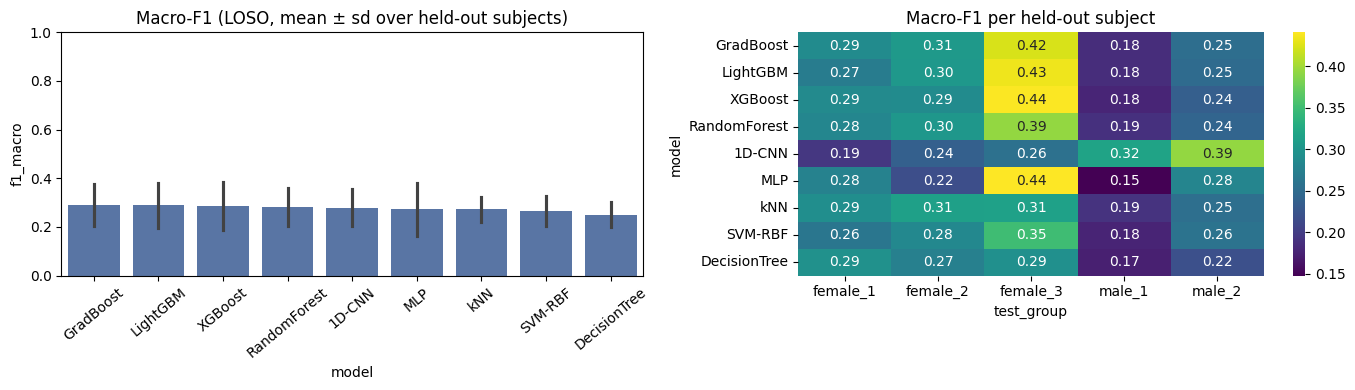

In [28]:
# ========== baseline evaluation table + "baseline to beat" 
def summarize(rows, models=None):
    df = pd.DataFrame(rows)
    if models is not None: df = df[df.model.isin(models)]
    cols = ["acc", "bal_acc", "prec_macro", "rec_macro", "f1_macro", "f1_weighted", "mcc", "kappa", "auc_ovr", "train_f1", "fit_s", "pred_s"]
    m, s = df.groupby("model")[cols].mean(), df.groupby("model")[cols].std()
    out = m.copy().astype(object)
    for c in cols: out[c] = [f"{a:.3f} ± {b:.3f}" if c not in ("fit_s", "pred_s") else f"{a:.1f}" for a, b in zip(m[c], s[c])]
    out["gap(train-test F1)"] = (m["train_f1"] - m["f1_macro"]).round(3)
    order = m["f1_macro"].sort_values(ascending=False).index
    return out.loc[order], m.loc[order]

BASELINES = [m for m in list(MODELS) + ["MLP", "1D-CNN"] if m != "LogReg"]
tab, num = summarize(ROWS, BASELINES)
display(tab.rename(columns={"fit_s": "train time (s/fold)", "pred_s": "infer time (s/fold)"}))
BEST_BASE = num["f1_macro"].idxmax()
print(f"\n>>> BASELINE TO BEAT: {BEST_BASE}  (macro-F1 = {num.loc[BEST_BASE,'f1_macro']:.3f}, acc = {num.loc[BEST_BASE,'acc']:.3f}, LOSO mean over {len(GROUPS)} held-out subjects)")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
d = pd.DataFrame(ROWS); d = d[d.model.isin(BASELINES)]
sns.barplot(data=d, x="model", y="f1_macro", order=num.index, errorbar="sd", ax=ax[0], color="#4c72b0"); ax[0].set_title("Macro-F1 (LOSO, mean ± sd over held-out subjects)")
ax[0].tick_params(axis="x", rotation=40); ax[0].set_ylim(0, 1)
sns.heatmap(d.pivot_table(index="model", columns="test_group", values="f1_macro").loc[num.index], annot=True, fmt=".2f", cmap="viridis", ax=ax[1]); ax[1].set_title("Macro-F1 per held-out subject")
plt.tight_layout(); plt.show()

In [12]:
# ============  (C) GNN model + settings ============
class STMGNet(nn.Module):
    def __init__(self, f_in=F_NODE, hid=32, n_layers=2, K=K_SEG, p=0.3, use_edges=True):
        super().__init__()
        self.K, self.N, self.use_edges = K, 2 * K, use_edges
        A_t = torch.zeros(self.N, self.N)
        for c in range(2):
            for t in range(K - 1):
                i = c * K + t; A_t[i, i + 1] = A_t[i + 1, i] = 1.0
        self.register_buffer("A_t", A_t); self.register_buffer("I", torch.eye(self.N))
        self.w_t = nn.Parameter(torch.tensor(0.5413)); self.w_c = nn.Parameter(torch.tensor(0.5413))
        self.inp = nn.Linear(f_in, hid); self.emb = nn.Parameter(0.02 * torch.randn(self.N, hid))
        self.lins  = nn.ModuleList([nn.Linear(hid, hid) for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(hid) for _ in range(n_layers)])
        self.drop = nn.Dropout(p)
        self.head = nn.Sequential(nn.Linear(2 * hid, hid), nn.ReLU(), nn.Dropout(p), nn.Linear(hid, N_CLS))

    def adjacency(self, e):
        B, K = e.shape
        if not self.use_edges: return self.I.expand(B, self.N, self.N)
        t = torch.arange(K, device=e.device)
        Ac = e.new_zeros(B, self.N, self.N); Ac[:, t, K + t] = e; Ac[:, K + t, t] = e
        A = F.softplus(self.w_t) * self.A_t + F.softplus(self.w_c) * Ac + self.I
        d = A.sum(-1).clamp_min(1e-6).pow(-0.5)
        return d.unsqueeze(-1) * A * d.unsqueeze(-2)

    def forward(self, x, e):
        A = self.adjacency(e); h = self.inp(x) + self.emb
        for lin, nrm in zip(self.lins, self.norms):
            h = h + self.drop(F.relu(nrm(A @ lin(h))))
        return self.head(torch.cat([h.mean(1), h.max(1).values], -1))

GNN_SETTINGS = dict(nodes=2 * K_SEG, node_features=F_NODE, hidden=32, gnn_layers=2, dropout=0.3, readout="mean||max",
                    optimizer="AdamW", lr=2e-3, weight_decay=1e-3, label_smoothing=0.05, batch_size=256,
                    max_epochs=60, early_stop_patience=8, lr_schedule="ReduceLROnPlateau(0.5, patience=2)",
                    loss="class-weighted CE", seed=SEED, validation="1 training subject (never the test subject)")
display(pd.Series(GNN_SETTINGS, name="STMG-Net settings").to_frame())
print("parameters:", sum(p.numel() for p in STMGNet().parameters()))

def prep_gnn(k, fold):
    Gz = znorm_by_group(D["G"], fold, axes=(0, 2))
    sc = MinMaxScaler().fit(Gz[fold["idx_tr"]].reshape(-1, F_NODE))
    Gs = sc.transform(Gz.reshape(-1, F_NODE)).reshape(len(Gz), 2 * K_SEG, F_NODE).astype(np.float32)
    return lambda idx: (Gs[idx], D["E"][idx])

,STMG-Net settings
nodes,10
node_features,7
hidden,32
gnn_layers,2
dropout,0.3
readout,mean||max
optimizer,AdamW
lr,0.002
weight_decay,0.001
label_smoothing,0.05


parameters: 5096


In [13]:
# ============ CELL 13: train GNN (LOSO) + ablation without edges ============
GNN_KW = dict(epochs=60, patience=8)
print("STMG-Net (full graph)");         run_torch("STMG-Net",             prep_gnn, lambda inp: STMGNet(),                **GNN_KW)
print("STMG-Net (no edges, ablation)"); run_torch("STMG-Net (no edges)",  prep_gnn, lambda inp: STMGNet(use_edges=False), **GNN_KW)

STMG-Net (full graph)
  [STMG-Net          ] test=female_1   acc=0.287 f1=0.209 | train_f1=0.372 | fit=   2.6s
  [STMG-Net          ] test=female_2   acc=0.268 f1=0.193 | train_f1=0.346 | fit=   2.5s
  [STMG-Net          ] test=female_3   acc=0.393 f1=0.323 | train_f1=0.315 | fit=   2.4s
  [STMG-Net          ] test=male_1     acc=0.235 f1=0.187 | train_f1=0.373 | fit=   2.6s
  [STMG-Net          ] test=male_2     acc=0.349 f1=0.306 | train_f1=0.340 | fit=   2.5s
  params: 5096
STMG-Net (no edges, ablation)
  [STMG-Net (no edges)] test=female_1   acc=0.293 f1=0.223 | train_f1=0.377 | fit=   2.1s
  [STMG-Net (no edges)] test=female_2   acc=0.248 f1=0.186 | train_f1=0.322 | fit=   1.9s
  [STMG-Net (no edges)] test=female_3   acc=0.481 f1=0.399 | train_f1=0.314 | fit=   2.1s
  [STMG-Net (no edges)] test=male_1     acc=0.230 f1=0.185 | train_f1=0.390 | fit=   1.9s
  [STMG-Net (no edges)] test=male_2     acc=0.365 f1=0.278 | train_f1=0.351 | fit=   2.1s
  params: 5096


,acc,bal_acc,prec_macro,rec_macro,f1_macro,f1_weighted,mcc,kappa,auc_ovr,train_f1,train time (s/fold),infer time (s/fold),gap(train-test F1)
model,,,,,,,,,,,,,
GradBoost,0.297 ± 0.086,0.297 ± 0.086,0.303 ± 0.086,0.297 ± 0.086,0.290 ± 0.087,0.290 ± 0.087,0.158 ± 0.104,0.157 ± 0.104,0.696 ± 0.098,0.807 ± 0.031,2.0,0.3,0.517
LightGBM,0.297 ± 0.093,0.297 ± 0.093,0.300 ± 0.092,0.297 ± 0.093,0.288 ± 0.092,0.288 ± 0.092,0.158 ± 0.112,0.156 ± 0.111,0.695 ± 0.099,0.849 ± 0.029,1.8,0.3,0.560
XGBoost,0.291 ± 0.096,0.291 ± 0.096,0.300 ± 0.092,0.291 ± 0.096,0.286 ± 0.097,0.286 ± 0.097,0.151 ± 0.116,0.149 ± 0.116,0.697 ± 0.097,0.792 ± 0.030,1.8,0.1,0.507
RandomForest,0.288 ± 0.079,0.288 ± 0.079,0.301 ± 0.067,0.288 ± 0.079,0.282 ± 0.076,0.282 ± 0.076,0.147 ± 0.096,0.145 ± 0.095,0.693 ± 0.090,0.857 ± 0.022,5.6,0.2,0.575
1D-CNN,0.330 ± 0.041,0.330 ± 0.041,0.310 ± 0.071,0.330 ± 0.041,0.280 ± 0.078,0.280 ± 0.078,0.212 ± 0.042,0.196 ± 0.049,0.737 ± 0.060,0.453 ± 0.073,2.3,0.0,0.173
MLP,0.287 ± 0.100,0.287 ± 0.100,0.291 ± 0.117,0.287 ± 0.100,0.273 ± 0.109,0.273 ± 0.109,0.147 ± 0.123,0.144 ± 0.121,0.703 ± 0.092,0.595 ± 0.040,2.2,0.0,0.322
kNN,0.281 ± 0.057,0.281 ± 0.057,0.283 ± 0.050,0.281 ± 0.057,0.273 ± 0.052,0.273 ± 0.052,0.139 ± 0.069,0.137 ± 0.068,0.663 ± 0.089,0.795 ± 0.029,0.1,0.3,0.522
SVM-RBF,0.277 ± 0.062,0.277 ± 0.062,0.284 ± 0.055,0.277 ± 0.062,0.266 ± 0.062,0.266 ± 0.062,0.135 ± 0.075,0.133 ± 0.074,0.684 ± 0.094,0.756 ± 0.032,3.7,3.0,0.490
STMG-Net (no edges),0.323 ± 0.102,0.323 ± 0.102,0.296 ± 0.130,0.323 ± 0.102,0.254 ± 0.089,0.254 ± 0.089,0.205 ± 0.135,0.188 ± 0.123,0.759 ± 0.081,0.351 ± 0.033,2.0,0.0,0.097


,macro-F1,Δ vs best baseline,acc,MCC
model,,,,
GradBoost,0.290,0.000,0.297,0.158
LightGBM,0.288,-0.002,0.297,0.158
XGBoost,0.286,-0.005,0.291,0.151
RandomForest,0.282,-0.008,0.288,0.147
1D-CNN,0.280,-0.011,0.330,0.212
MLP,0.273,-0.018,0.287,0.147
kNN,0.273,-0.018,0.281,0.139
SVM-RBF,0.266,-0.024,0.277,0.135
STMG-Net (no edges),0.254,-0.036,0.323,0.205



Per-subject macro-F1 difference (positive = GNN better):


test_group,female_1,female_2,female_3,male_1,male_2
STMG-Net − GradBoost,-0.078,-0.112,-0.1,0.003,0.054


GNN beats GradBoost on 2 / 5 held-out subjects; mean Δ macro-F1 = -0.047.  (n = 5 subjects -> indicative, not statistically conclusive.)


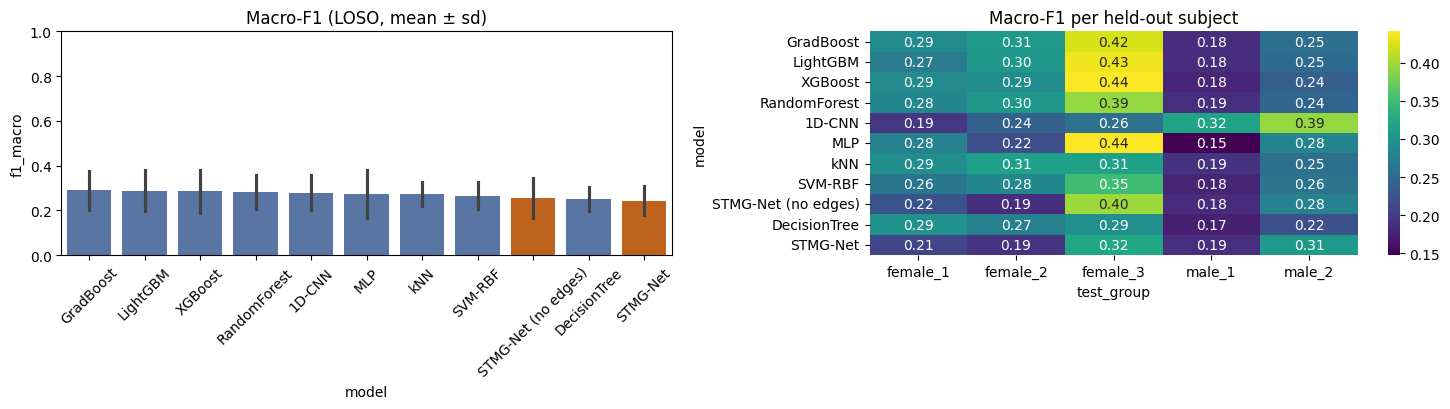

              precision    recall  f1-score   support

 Cylindrical      0.359     0.424     0.389      2760
         Tip      0.243     0.392     0.300      2760
        Hook      0.052     0.025     0.034      2760
      Palmar      0.083     0.006     0.011      2760
   Spherical      0.488     0.684     0.569      2760
     Lateral      0.245     0.307     0.272      2760

    accuracy                          0.306     16560
   macro avg      0.245     0.306     0.263     16560
weighted avg      0.245     0.306     0.263     16560



In [30]:
# ============  first results — GNN vs baselines ============
ALL = BASELINES + ["STMG-Net", "STMG-Net (no edges)"]
tab, num = summarize(ROWS, ALL)
display(tab.rename(columns={"fit_s": "train time (s/fold)", "pred_s": "infer time (s/fold)"}))

best_f1 = num.loc[BEST_BASE, "f1_macro"]
cmp = pd.DataFrame({"macro-F1": num["f1_macro"], "Δ vs best baseline": num["f1_macro"] - best_f1,
                    "acc": num["acc"], "MCC": num["mcc"]}).round(3)
display(cmp)
d = pd.DataFrame(ROWS); per = d.pivot_table(index="model", columns="test_group", values="f1_macro")
delta = (per.loc["STMG-Net"] - per.loc[BEST_BASE]).rename("STMG-Net − " + BEST_BASE)
print("\nPer-subject macro-F1 difference (positive = GNN better):"); display(delta.round(3).to_frame().T)
print(f"GNN beats {BEST_BASE} on {(delta > 0).sum()} / {len(delta)} held-out subjects; "
      f"mean Δ macro-F1 = {delta.mean():+.3f}.  (n = {len(delta)} subjects -> indicative, not statistically conclusive.)")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
dd = d[d.model.isin(ALL)]
sns.barplot(data=dd, x="model", y="f1_macro", order=num.index, errorbar="sd", ax=ax[0],
            palette=["#d95f02" if m.startswith("STMG") else "#4c72b0" for m in num.index]); ax[0].tick_params(axis="x", rotation=45)
ax[0].set_title("Macro-F1 (LOSO, mean ± sd)"); ax[0].set_ylim(0, 1)
sns.heatmap(per.loc[num.index], annot=True, fmt=".2f", cmap="viridis", ax=ax[1]); ax[1].set_title("Macro-F1 per held-out subject")
plt.tight_layout(); plt.show()
print(classification_report(np.concatenate(PRED["STMG-Net"]["y"]), np.concatenate(PRED["STMG-Net"]["p"]), target_names=CLASS_NAMES, digits=3))

In [15]:
# ============ leakage checks — proof that nothing leaks ============
fold = FOLDS[0]; Z, tr, te = Z_TAB[0], fold["idx_tr"], fold["idx_te"]; y = D["y"]
print("1) subject overlap train/test :", set(D["grp"][tr]) & set(D["grp"][te]) or "none")
print("2) trial overlap  train/test  :", set(D["trial"][tr]) & set(D["trial"][te]) or "none")
print("3) trial overlap  cal/test    :", set(D["trial"][fold["idx_cal"]]) & set(D["trial"][te]) or "none")
print("4) scaler/PCA/selector are inside sklearn Pipeline -> fitted on training subjects only (see make_prep)")

rs = np.random.RandomState(0); y_perm = y[tr].copy(); rs.shuffle(y_perm)
pipe = Pipeline(make_prep() + [("clf", LogisticRegression(max_iter=2000))]).fit(Z[tr], y_perm)
print(f"5) permuted-label LogReg  : test acc = {accuracy_score(y[te], pipe.predict(Z[te])):.3f}  (chance = {1/N_CLS:.3f})  -> must be ≈ chance")

Zr = Z_TAB[0]
rf = lambda: Pipeline(make_prep() + [("clf", RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=SEED))])
rand_acc = cross_val_score(rf(), Zr, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="accuracy", n_jobs=1).mean()
loso_acc = cross_val_score(rf(), Zr, y, cv=GroupKFold(len(GROUPS)), groups=D["grp"], scoring="accuracy", n_jobs=1).mean()
print(f"6) RandomForest  random-window-split acc = {rand_acc:.3f}   vs   subject-independent (LOSO) acc = {loso_acc:.3f}")
print("   -> the random split is over-optimistic (windows of the same trial are near-duplicates). We therefore report ONLY LOSO numbers.")

1) subject overlap train/test : none
2) trial overlap  train/test  : none
3) trial overlap  cal/test    : none
4) scaler/PCA/selector are inside sklearn Pipeline -> fitted on training subjects only (see make_prep)
5) permuted-label LogReg  : test acc = 0.157  (chance = 0.167)  -> must be ≈ chance
6) RandomForest  random-window-split acc = 0.734   vs   subject-independent (LOSO) acc = 0.291
   -> the random split is over-optimistic (windows of the same trial are near-duplicates). We therefore report ONLY LOSO numbers.


In [16]:
# =========== strongly-regularised baselines, inner-CV tuning on TRAIN subjects ============
def run_sklearn2(name, make_clf, grid=None, use_cal=False, cal_w=5):
    reset(name); y = D["y"]
    for k, fold in enumerate(FOLDS):
        Z, tr, te, cal = Z_TAB[k], fold["idx_tr"], fold["idx_te"], fold["idx_cal"]
        pipe = Pipeline(make_prep() + [("clf", make_clf())])
        t0 = time.time()
        if use_cal:
            idx = np.r_[tr, cal]; sw = np.r_[np.ones(len(tr)), np.full(len(cal), float(cal_w))]
            assert set(D["trial"][cal]).isdisjoint(set(D["trial"][te]))
            pipe.fit(Z[idx], y[idx], clf__sample_weight=sw)
        elif grid:
            gs = GridSearchCV(pipe, grid, cv=GroupKFold(n_splits=len(fold["tr_groups"])), scoring="f1_macro", n_jobs=1)
            gs.fit(Z[tr], y[tr], groups=D["grp"][tr]); pipe = gs.best_estimator_
        else:
            pipe.fit(Z[tr], y[tr])
        t_fit = time.time() - t0
        t0 = time.time(); p = pipe.predict(Z[te]); S = get_scores(pipe, Z[te]); t_pred = time.time() - t0
        trs = np.random.RandomState(SEED).choice(tr, min(4000, len(tr)), replace=False)
        record(name, fold, y[te], p, S, y[trs], pipe.predict(Z[trs]), t_fit, t_pred)

REG = {
 "LogReg (reg)": (lambda: LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced"), {"clf__C": [0.003, 0.01, 0.1]}),
 "SVM-RBF (reg)": (lambda: SVC(kernel="rbf", C=0.5, gamma=0.02, class_weight="balanced"), {"clf__C": [0.1, 0.5], "clf__gamma": [0.005, 0.02]}),
 "kNN (reg)": (lambda: KNeighborsClassifier(n_neighbors=101, n_jobs=-1), {"clf__n_neighbors": [51, 101, 201]}),
 "DecisionTree (reg)": (lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=100, class_weight="balanced", random_state=SEED), {"clf__max_depth": [3, 4, 5], "clf__min_samples_leaf": [100, 300]}),
 "RandomForest (reg)": (lambda: RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_leaf=60, max_features=0.5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
                        {"clf__max_depth": [3, 5, 8], "clf__min_samples_leaf": [30, 100]}),
 "GradBoost (reg)": (lambda: HistGradientBoostingClassifier(max_iter=60, learning_rate=0.05, max_depth=2, min_samples_leaf=100, l2_regularization=10.0, early_stopping=False, random_state=SEED),
                     {"clf__max_depth": [2, 3], "clf__max_iter": [40, 80]}),
}
if xgb is not None:
    REG["XGBoost (reg)"] = (lambda: xgb.XGBClassifier(n_estimators=60, max_depth=2, learning_rate=0.05, subsample=0.7, colsample_bytree=0.6, min_child_weight=30, reg_lambda=20.0,
                                                      tree_method="hist", n_jobs=-1, random_state=SEED, verbosity=0), {"clf__max_depth": [2, 3], "clf__n_estimators": [40, 80]})
if lgb is not None:
    REG["LightGBM (reg)"] = (lambda: lgb.LGBMClassifier(n_estimators=60, num_leaves=4, learning_rate=0.05, subsample=0.7, subsample_freq=1, colsample_bytree=0.6, min_child_samples=150,
                                                        reg_lambda=20.0, n_jobs=-1, random_state=SEED, verbose=-1), {"clf__num_leaves": [4, 8], "clf__n_estimators": [40, 80]})
for name, (mk, grid) in REG.items():
    print(name); run_sklearn2(name, mk, grid)

LogReg (reg)
  [LogReg (reg)      ] test=female_1   acc=0.250 f1=0.190 | train_f1=0.529 | fit=   1.5s
  [LogReg (reg)      ] test=female_2   acc=0.344 f1=0.325 | train_f1=0.521 | fit=   1.5s
  [LogReg (reg)      ] test=female_3   acc=0.534 f1=0.536 | train_f1=0.539 | fit=   1.8s
  [LogReg (reg)      ] test=male_1     acc=0.226 f1=0.183 | train_f1=0.563 | fit=   1.6s
  [LogReg (reg)      ] test=male_2     acc=0.248 f1=0.265 | train_f1=0.587 | fit=   1.7s
SVM-RBF (reg)
  [SVM-RBF (reg)     ] test=female_1   acc=0.242 f1=0.227 | train_f1=0.519 | fit= 146.0s
  [SVM-RBF (reg)     ] test=female_2   acc=0.367 f1=0.337 | train_f1=0.504 | fit= 148.9s
  [SVM-RBF (reg)     ] test=female_3   acc=0.553 f1=0.549 | train_f1=0.514 | fit= 152.2s
  [SVM-RBF (reg)     ] test=male_1     acc=0.233 f1=0.173 | train_f1=0.550 | fit= 147.0s
  [SVM-RBF (reg)     ] test=male_2     acc=0.220 f1=0.221 | train_f1=0.581 | fit= 147.5s
kNN (reg)
  [kNN (reg)         ] test=female_1   acc=0.320 f1=0.304 | train_f1=0.71

In [17]:
# ============  regularised MLP (zero-shot) + trainer that can also use X_Cal ============
class MLPreg(nn.Module):
    def __init__(self, d, h=32, p=0.5):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, N_CLS))
    def forward(self, x): return self.net(x)

def run_torch_cal(name, prep_fn, model_fn, cal_w=0, **kw):
    reset(name); y = D["y"]
    for k, fold in enumerate(FOLDS):
        get = prep_fn(k, fold); tr, te, cal = fold["idx_tr"], fold["idx_te"], fold["idx_cal"]
        va  = tr[D["grp"][tr] == fold["val_g"]]; fit = tr[D["grp"][tr] != fold["val_g"]]
        if cal_w: assert set(D["trial"][cal]).isdisjoint(set(D["trial"][te])); fit = np.r_[fit, np.repeat(cal, cal_w)]
        torch.manual_seed(SEED + k); np.random.seed(SEED + k)
        model = model_fn(get(fit[:4]))
        t0 = time.time(); model, ep = fit_torch(model, get(fit), y[fit], get(va), y[va], **kw); t_fit = time.time() - t0
        t0 = time.time(); S = F.softmax(predict_logits(model, get(te)), 1).numpy(); t_pred = time.time() - t0
        trs = np.random.RandomState(SEED).choice(tr, min(4000, len(tr)), replace=False)
        record(name, fold, y[te], S.argmax(1), S, y[trs], predict_logits(model, get(trs)).argmax(1).numpy(), t_fit, t_pred, ep)

run_torch_cal("MLP (reg)", prep_mlp, lambda inp: MLPreg(inp[0].shape[1]), wd=1e-2, epochs=40, patience=7)

  [MLP (reg)         ] test=female_1   acc=0.266 f1=0.217 | train_f1=0.545 | fit=   1.3s
  [MLP (reg)         ] test=female_2   acc=0.287 f1=0.271 | train_f1=0.551 | fit=   1.2s
  [MLP (reg)         ] test=female_3   acc=0.549 f1=0.534 | train_f1=0.410 | fit=   1.0s
  [MLP (reg)         ] test=male_1     acc=0.253 f1=0.210 | train_f1=0.524 | fit=   1.3s
  [MLP (reg)         ] test=male_2     acc=0.304 f1=0.310 | train_f1=0.491 | fit=   1.2s


In [18]:
# =======regularised 1D-CNN (zero-shot) + trainer that can also use X_Cal ============
class CNN1Dreg(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()
        def blk(i, o, k): return nn.Sequential(nn.Conv1d(i, o, k, padding=k // 2), nn.BatchNorm1d(o), nn.ReLU())
        self.f = nn.Sequential(blk(2, 8, 7), nn.MaxPool1d(2), blk(8, 16, 5), nn.MaxPool1d(2), blk(16, 32, 3), nn.AdaptiveAvgPool1d(1))
        self.h = nn.Sequential(nn.Flatten(), nn.Dropout(p), nn.Linear(32, N_CLS))
    def forward(self, x): return self.h(self.f(x))

def run_torch_cal(name, prep_fn, model_fn, cal_w=0, **kw):
    reset(name); y = D["y"]
    for k, fold in enumerate(FOLDS):
        get = prep_fn(k, fold); tr, te, cal = fold["idx_tr"], fold["idx_te"], fold["idx_cal"]
        va  = tr[D["grp"][tr] == fold["val_g"]]; fit = tr[D["grp"][tr] != fold["val_g"]]
        if cal_w: assert set(D["trial"][cal]).isdisjoint(set(D["trial"][te])); fit = np.r_[fit, np.repeat(cal, cal_w)]
        torch.manual_seed(SEED + k); np.random.seed(SEED + k)
        model = model_fn(get(fit[:4]))
        t0 = time.time(); model, ep = fit_torch(model, get(fit), y[fit], get(va), y[va], **kw); t_fit = time.time() - t0
        t0 = time.time(); S = F.softmax(predict_logits(model, get(te)), 1).numpy(); t_pred = time.time() - t0
        trs = np.random.RandomState(SEED).choice(tr, min(4000, len(tr)), replace=False)
        record(name, fold, y[te], S.argmax(1), S, y[trs], predict_logits(model, get(trs)).argmax(1).numpy(), t_fit, t_pred, ep)

CAL_W = 5
print("1D-CNN (reg)")
run_torch_cal("1D-CNN (reg)",      prep_cnn, lambda inp: CNN1Dreg(),            wd=1e-2, epochs=30, patience=5)   # zero-shot
print("1D-CNN (reg) +Cal")
run_torch_cal("1D-CNN (reg) +Cal", prep_cnn, lambda inp: CNN1Dreg(), cal_w=CAL_W, wd=1e-2, epochs=30, patience=5)  # with X_Cal

1D-CNN (reg)
  [1D-CNN (reg)      ] test=female_1   acc=0.306 f1=0.280 | train_f1=0.465 | fit=   1.4s
  [1D-CNN (reg)      ] test=female_2   acc=0.246 f1=0.210 | train_f1=0.531 | fit=   1.8s
  [1D-CNN (reg)      ] test=female_3   acc=0.314 f1=0.252 | train_f1=0.443 | fit=   1.4s
  [1D-CNN (reg)      ] test=male_1     acc=0.195 f1=0.201 | train_f1=0.414 | fit=   1.4s
  [1D-CNN (reg)      ] test=male_2     acc=0.317 f1=0.294 | train_f1=0.500 | fit=   1.8s
1D-CNN (reg) +Cal
  [1D-CNN (reg) +Cal ] test=female_1   acc=0.487 f1=0.447 | train_f1=0.480 | fit=   1.8s
  [1D-CNN (reg) +Cal ] test=female_2   acc=0.497 f1=0.453 | train_f1=0.620 | fit=   2.9s
  [1D-CNN (reg) +Cal ] test=female_3   acc=0.506 f1=0.471 | train_f1=0.442 | fit=   1.9s
  [1D-CNN (reg) +Cal ] test=male_1     acc=0.380 f1=0.408 | train_f1=0.366 | fit=   2.0s
  [1D-CNN (reg) +Cal ] test=male_2     acc=0.709 f1=0.716 | train_f1=0.463 | fit=   2.2s


,acc,bal_acc,prec_macro,rec_macro,f1_macro,f1_weighted,mcc,kappa,auc_ovr,train_f1,train time (s/fold),infer time (s/fold),gap(train-test F1)
model,,,,,,,,,,,,,
MLP (reg),0.332 ± 0.123,0.332 ± 0.123,0.330 ± 0.157,0.332 ± 0.123,0.308 ± 0.132,0.308 ± 0.132,0.202 ± 0.150,0.198 ± 0.148,0.740 ± 0.078,0.504 ± 0.058,1.2,0.0,0.196
RandomForest (reg),0.330 ± 0.075,0.330 ± 0.075,0.306 ± 0.063,0.330 ± 0.075,0.305 ± 0.071,0.305 ± 0.071,0.200 ± 0.093,0.196 ± 0.091,0.732 ± 0.067,0.577 ± 0.033,54.7,0.2,0.272
SVM-RBF (reg),0.323 ± 0.141,0.323 ± 0.141,0.338 ± 0.144,0.323 ± 0.141,0.301 ± 0.151,0.301 ± 0.151,0.194 ± 0.174,0.188 ± 0.170,0.749 ± 0.080,0.534 ± 0.031,148.3,5.2,0.232
LogReg (reg),0.320 ± 0.128,0.320 ± 0.128,0.312 ± 0.156,0.320 ± 0.128,0.300 ± 0.144,0.300 ± 0.144,0.188 ± 0.154,0.184 ± 0.153,0.751 ± 0.083,0.548 ± 0.027,1.6,0.0,0.248
DecisionTree (reg),0.300 ± 0.086,0.300 ± 0.086,0.329 ± 0.040,0.300 ± 0.086,0.296 ± 0.084,0.296 ± 0.084,0.161 ± 0.105,0.160 ± 0.104,0.714 ± 0.057,0.583 ± 0.057,3.3,0.0,0.286
LightGBM (reg),0.290 ± 0.083,0.290 ± 0.083,0.303 ± 0.063,0.290 ± 0.083,0.281 ± 0.080,0.281 ± 0.080,0.150 ± 0.101,0.148 ± 0.100,0.703 ± 0.069,0.646 ± 0.040,5.7,0.0,0.364
XGBoost (reg),0.288 ± 0.081,0.288 ± 0.081,0.301 ± 0.057,0.288 ± 0.081,0.280 ± 0.075,0.280 ± 0.075,0.148 ± 0.099,0.146 ± 0.098,0.707 ± 0.084,0.637 ± 0.054,6.7,0.0,0.357
GradBoost (reg),0.274 ± 0.063,0.274 ± 0.063,0.280 ± 0.061,0.274 ± 0.063,0.267 ± 0.066,0.267 ± 0.066,0.131 ± 0.076,0.129 ± 0.076,0.712 ± 0.070,0.650 ± 0.051,8.2,0.1,0.383
kNN (reg),0.273 ± 0.058,0.273 ± 0.058,0.279 ± 0.045,0.273 ± 0.058,0.266 ± 0.052,0.266 ± 0.052,0.129 ± 0.071,0.127 ± 0.070,0.680 ± 0.092,0.759 ± 0.051,3.8,0.4,0.493


Best regularised baseline: MLP (reg)


,macro-F1,Δ vs best reg. baseline,acc,MCC
model,,,,
MLP (reg),0.308,0.000,0.332,0.202
RandomForest (reg),0.305,-0.004,0.330,0.200
SVM-RBF (reg),0.301,-0.007,0.323,0.194
LogReg (reg),0.300,-0.008,0.320,0.188
DecisionTree (reg),0.296,-0.012,0.300,0.161
LightGBM (reg),0.281,-0.027,0.290,0.150
XGBoost (reg),0.280,-0.028,0.288,0.148
GradBoost (reg),0.267,-0.042,0.274,0.131
kNN (reg),0.266,-0.042,0.273,0.129



Per-subject macro-F1 difference vs MLP (reg) (positive = GNN better):


test_group,female_1,female_2,female_3,male_1,male_2
STMG-Net − MLP (reg),-0.007,-0.078,-0.211,-0.023,-0.004


GNN beats MLP (reg) on 0 / 5 held-out subjects; mean Δ macro-F1 = -0.065.  (n = 5 subjects -> indicative, not statistically conclusive.)

Per-subject macro-F1 difference vs 1D-CNN (reg) (positive = GNN better):


test_group,female_1,female_2,female_3,male_1,male_2
STMG-Net − 1D-CNN (reg),-0.07,-0.018,0.071,-0.013,0.012


GNN beats 1D-CNN (reg) on 2 / 5 held-out subjects; mean Δ macro-F1 = -0.004.  (n = 5 subjects -> indicative, not statistically conclusive.)


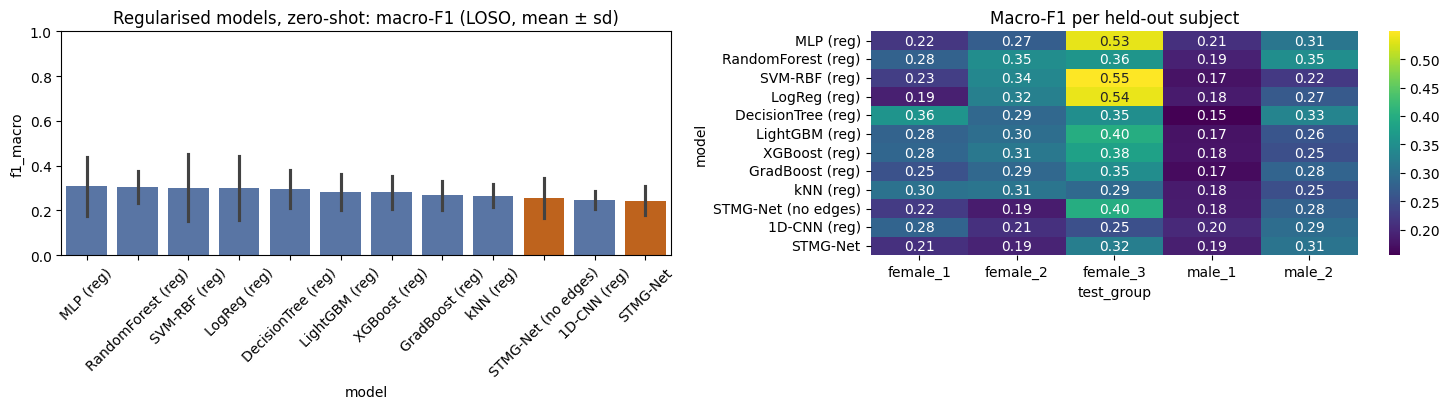

In [32]:
# ============  regularised models (zero-shot): GNN vs regularised baselines ============
d = pd.DataFrame(ROWS)
REG_NAMES = [m for m in list(REG.keys()) + ["MLP (reg)", "1D-CNN (reg)"] if m in set(d.model)]
ALL_REG = REG_NAMES + ["STMG-Net", "STMG-Net (no edges)"]

tab, num = summarize(ROWS, ALL_REG)
display(tab.rename(columns={"fit_s": "train time (s/fold)", "pred_s": "infer time (s/fold)"}))

BEST_REG = num.loc[REG_NAMES, "f1_macro"].idxmax()
best_f1 = num.loc[BEST_REG, "f1_macro"]
cmp = pd.DataFrame({"macro-F1": num["f1_macro"], "Δ vs best reg. baseline": num["f1_macro"] - best_f1,
                    "acc": num["acc"], "MCC": num["mcc"]}).round(3)
print(f"Best regularised baseline: {BEST_REG}")
display(cmp)

# ---- per-subject: STMG-Net vs best regularised baseline, and vs 1D-CNN (reg) ----
per = d.pivot_table(index="model", columns="test_group", values="f1_macro")
for ref in dict.fromkeys([BEST_REG, "1D-CNN (reg)"]):
    if ref not in per.index:
        continue
    delta = (per.loc["STMG-Net"] - per.loc[ref]).rename("STMG-Net − " + ref)
    print(f"\nPer-subject macro-F1 difference vs {ref} (positive = GNN better):")
    display(delta.round(3).to_frame().T)
    print(f"GNN beats {ref} on {(delta > 0).sum()} / {len(delta)} held-out subjects; "
          f"mean Δ macro-F1 = {delta.mean():+.3f}.  (n = {len(delta)} subjects -> indicative, not statistically conclusive.)")

# ---- plots ----
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
dd = d[d.model.isin(ALL_REG)]
sns.barplot(data=dd, x="model", y="f1_macro", order=num.index, errorbar="sd", ax=ax[0],
            palette=["#d95f02" if m.startswith("STMG") else "#4c72b0" for m in num.index])
ax[0].tick_params(axis="x", rotation=45); ax[0].set_ylim(0, 1)
ax[0].set_title("Regularised models, zero-shot: macro-F1 (LOSO, mean ± sd)")
sns.heatmap(per.loc[num.index], annot=True, fmt=".2f", cmap="viridis", ax=ax[1])
ax[1].set_title("Macro-F1 per held-out subject")
plt.tight_layout(); plt.show()

In [22]:
# ============  calibrated / adaptation setting — ALL models (8 classical + 2 deep + 1 GNN) ============
# train subjects + X_Cal (up-weighted); test = X_Test only
CAL_W = 5

def run_sklearn_cal(name, make_clf, cal_w=CAL_W, replicate=False):
    # replicate=True: copy the calibration windows cal_w times (needed for models without sample_weight, e.g. kNN)
    reset(name); y = D["y"]
    for k, fold in enumerate(FOLDS):
        Z, tr, te, cal = Z_TAB[k], fold["idx_tr"], fold["idx_te"], fold["idx_cal"]
        assert set(D["trial"][cal]).isdisjoint(set(D["trial"][te]))
        pipe = Pipeline(make_prep() + [("clf", make_clf())]); t0 = time.time()
        if replicate:
            idx = np.r_[tr, np.repeat(cal, cal_w)]; pipe.fit(Z[idx], y[idx])
        else:
            idx = np.r_[tr, cal]; sw = np.r_[np.ones(len(tr)), np.full(len(cal), float(cal_w))]
            pipe.fit(Z[idx], y[idx], clf__sample_weight=sw)
        t_fit = time.time() - t0
        t0 = time.time(); p = pipe.predict(Z[te]); S = get_scores(pipe, Z[te]); t_pred = time.time() - t0
        trs = np.random.RandomState(SEED).choice(tr, min(4000, len(tr)), replace=False)
        record(name, fold, y[te], p, S, y[trs], pipe.predict(Z[trs]), t_fit, t_pred)

# ---- 8 classical models 
CAL = {
 "LogReg +Cal":       (lambda: LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced"), False),
 "SVM-RBF +Cal":      (lambda: SVC(kernel="rbf", C=0.5, gamma=0.02, class_weight="balanced"), False),
 "kNN +Cal":          (lambda: KNeighborsClassifier(n_neighbors=101, n_jobs=-1), True),
 "DecisionTree +Cal": (lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=100, class_weight="balanced", random_state=SEED), False),
 "RandomForest +Cal": (lambda: RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=60, max_features=0.5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED), False),
 "GradBoost +Cal":    (lambda: HistGradientBoostingClassifier(max_iter=60, learning_rate=0.05, max_depth=2, min_samples_leaf=100, l2_regularization=10.0, early_stopping=False, random_state=SEED), False),
}
if xgb is not None:
    CAL["XGBoost +Cal"] = (lambda: xgb.XGBClassifier(n_estimators=60, max_depth=2, learning_rate=0.05, subsample=0.7, colsample_bytree=0.6, min_child_weight=30, reg_lambda=20.0,
                                                     tree_method="hist", n_jobs=-1, random_state=SEED, verbosity=0), False)
if lgb is not None:
    CAL["LightGBM +Cal"] = (lambda: lgb.LGBMClassifier(n_estimators=80, num_leaves=4, learning_rate=0.05, subsample=0.7, subsample_freq=1, colsample_bytree=0.6, min_child_samples=150,
                                                       reg_lambda=20.0, n_jobs=-1, random_state=SEED, verbose=-1), False)
for name, (mk, rep) in CAL.items():
    print(name); run_sklearn_cal(name, mk, replicate=rep)



LogReg +Cal
  [LogReg +Cal       ] test=female_1   acc=0.546 f1=0.514 | train_f1=0.559 | fit=   0.3s
  [LogReg +Cal       ] test=female_2   acc=0.441 f1=0.417 | train_f1=0.584 | fit=   0.2s
  [LogReg +Cal       ] test=female_3   acc=0.726 f1=0.714 | train_f1=0.518 | fit=   0.3s
  [LogReg +Cal       ] test=male_1     acc=0.373 f1=0.372 | train_f1=0.593 | fit=   0.3s
  [LogReg +Cal       ] test=male_2     acc=0.695 f1=0.697 | train_f1=0.518 | fit=   0.3s
SVM-RBF +Cal
  [SVM-RBF +Cal      ] test=female_1   acc=0.539 f1=0.472 | train_f1=0.531 | fit=  10.7s
  [SVM-RBF +Cal      ] test=female_2   acc=0.435 f1=0.423 | train_f1=0.549 | fit=  10.2s
  [SVM-RBF +Cal      ] test=female_3   acc=0.679 f1=0.653 | train_f1=0.493 | fit=  11.3s
  [SVM-RBF +Cal      ] test=male_1     acc=0.390 f1=0.355 | train_f1=0.559 | fit=  10.4s
  [SVM-RBF +Cal      ] test=male_2     acc=0.676 f1=0.670 | train_f1=0.486 | fit=  10.7s
kNN +Cal
  [kNN +Cal          ] test=female_1   acc=0.707 f1=0.702 | train_f1=0.696 |

In [23]:
# ============ FIX: MLPreg definition + run the 3 remaining +Cal models ============
class MLPreg(nn.Module):
    def __init__(self, d, h=32, p=0.5):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, N_CLS))
    def forward(self, x): return self.net(x)

CAL_W = 5
print("MLP (reg) +Cal");      run_torch_cal("MLP (reg) +Cal",      prep_mlp, lambda inp: MLPreg(inp[0].shape[1]), cal_w=CAL_W, wd=1e-2, epochs=40, patience=7)
print("1D-CNN (reg) +Cal");   run_torch_cal("1D-CNN (reg) +Cal",   prep_cnn, lambda inp: CNN1Dreg(),              cal_w=CAL_W, wd=1e-2, epochs=30, patience=5)
print("STMG-Net +Cal");       run_torch_cal("STMG-Net +Cal",       prep_gnn, lambda inp: STMGNet(),               cal_w=CAL_W, epochs=60, patience=8)

MLP (reg) +Cal
  [MLP (reg) +Cal    ] test=female_1   acc=0.502 f1=0.454 | train_f1=0.486 | fit=   1.5s
  [MLP (reg) +Cal    ] test=female_2   acc=0.404 f1=0.387 | train_f1=0.607 | fit=   1.9s
  [MLP (reg) +Cal    ] test=female_3   acc=0.703 f1=0.690 | train_f1=0.425 | fit=   1.3s
  [MLP (reg) +Cal    ] test=male_1     acc=0.422 f1=0.430 | train_f1=0.471 | fit=   1.3s
  [MLP (reg) +Cal    ] test=male_2     acc=0.631 f1=0.641 | train_f1=0.420 | fit=   1.3s
1D-CNN (reg) +Cal
  [1D-CNN (reg) +Cal ] test=female_1   acc=0.486 f1=0.446 | train_f1=0.480 | fit=   1.8s
  [1D-CNN (reg) +Cal ] test=female_2   acc=0.490 f1=0.445 | train_f1=0.611 | fit=   2.7s
  [1D-CNN (reg) +Cal ] test=female_3   acc=0.508 f1=0.473 | train_f1=0.445 | fit=   1.8s
  [1D-CNN (reg) +Cal ] test=male_1     acc=0.380 f1=0.408 | train_f1=0.365 | fit=   1.8s
  [1D-CNN (reg) +Cal ] test=male_2     acc=0.706 f1=0.712 | train_f1=0.463 | fit=   2.3s
STMG-Net +Cal
  [STMG-Net +Cal     ] test=female_1   acc=0.446 f1=0.436 | tra

,acc,bal_acc,prec_macro,rec_macro,f1_macro,f1_weighted,mcc,kappa,auc_ovr,train_f1,train time (s/fold),infer time (s/fold),gap(train-test F1)
model,,,,,,,,,,,,,
kNN +Cal,0.668 ± 0.115,0.668 ± 0.115,0.679 ± 0.117,0.668 ± 0.115,0.667 ± 0.118,0.667 ± 0.118,0.605 ± 0.137,0.602 ± 0.138,0.911 ± 0.053,0.713 ± 0.033,0.1,0.4,0.046
LightGBM +Cal,0.622 ± 0.151,0.622 ± 0.151,0.633 ± 0.143,0.622 ± 0.151,0.616 ± 0.154,0.616 ± 0.154,0.550 ± 0.179,0.546 ± 0.181,0.892 ± 0.061,0.638 ± 0.042,0.4,0.0,0.022
GradBoost +Cal,0.605 ± 0.155,0.605 ± 0.155,0.617 ± 0.147,0.605 ± 0.155,0.595 ± 0.162,0.595 ± 0.162,0.530 ± 0.183,0.525 ± 0.186,0.885 ± 0.059,0.613 ± 0.048,0.5,0.1,0.019
RandomForest +Cal,0.605 ± 0.134,0.605 ± 0.134,0.621 ± 0.130,0.605 ± 0.134,0.594 ± 0.140,0.594 ± 0.140,0.532 ± 0.159,0.526 ± 0.160,0.886 ± 0.058,0.611 ± 0.046,3.1,0.2,0.017
XGBoost +Cal,0.587 ± 0.173,0.587 ± 0.173,0.591 ± 0.176,0.587 ± 0.173,0.575 ± 0.183,0.575 ± 0.183,0.510 ± 0.205,0.505 ± 0.208,0.876 ± 0.064,0.583 ± 0.048,0.4,0.0,0.008
LogReg +Cal,0.556 ± 0.154,0.556 ± 0.154,0.567 ± 0.150,0.556 ± 0.154,0.543 ± 0.157,0.543 ± 0.157,0.474 ± 0.185,0.468 ± 0.185,0.864 ± 0.069,0.554 ± 0.035,0.3,0.0,0.012
MLP (reg) +Cal,0.532 ± 0.131,0.532 ± 0.131,0.567 ± 0.148,0.532 ± 0.131,0.520 ± 0.136,0.520 ± 0.136,0.447 ± 0.161,0.439 ± 0.157,0.863 ± 0.060,0.482 ± 0.076,1.5,0.0,-0.039
SVM-RBF +Cal,0.544 ± 0.134,0.544 ± 0.134,0.547 ± 0.145,0.544 ± 0.134,0.515 ± 0.141,0.515 ± 0.141,0.467 ± 0.164,0.453 ± 0.160,0.851 ± 0.054,0.523 ± 0.033,10.7,5.2,0.009
1D-CNN (reg) +Cal,0.514 ± 0.119,0.514 ± 0.119,0.541 ± 0.110,0.514 ± 0.119,0.497 ± 0.123,0.497 ± 0.123,0.436 ± 0.141,0.417 ± 0.142,0.885 ± 0.040,0.473 ± 0.089,2.1,0.0,-0.024


Best calibrated baseline: kNN +Cal


,macro-F1,Δ vs best cal. baseline,acc,MCC
model,,,,
kNN +Cal,0.667,0.000,0.668,0.605
LightGBM +Cal,0.616,-0.051,0.622,0.550
GradBoost +Cal,0.595,-0.072,0.605,0.530
RandomForest +Cal,0.594,-0.072,0.605,0.532
XGBoost +Cal,0.575,-0.092,0.587,0.510
LogReg +Cal,0.543,-0.124,0.556,0.474
MLP (reg) +Cal,0.520,-0.146,0.532,0.447
SVM-RBF +Cal,0.515,-0.152,0.544,0.467
1D-CNN (reg) +Cal,0.497,-0.170,0.514,0.436



Per-subject macro-F1 difference vs kNN +Cal (positive = GNN better):


test_group,female_1,female_2,female_3,male_1,male_2
STMG-Net +Cal − kNN +Cal,-0.267,-0.138,-0.276,-0.38,-0.321


GNN beats kNN +Cal on 0 / 5 held-out subjects; mean Δ macro-F1 = -0.276.  (n = 5 subjects -> indicative, not statistically conclusive.)


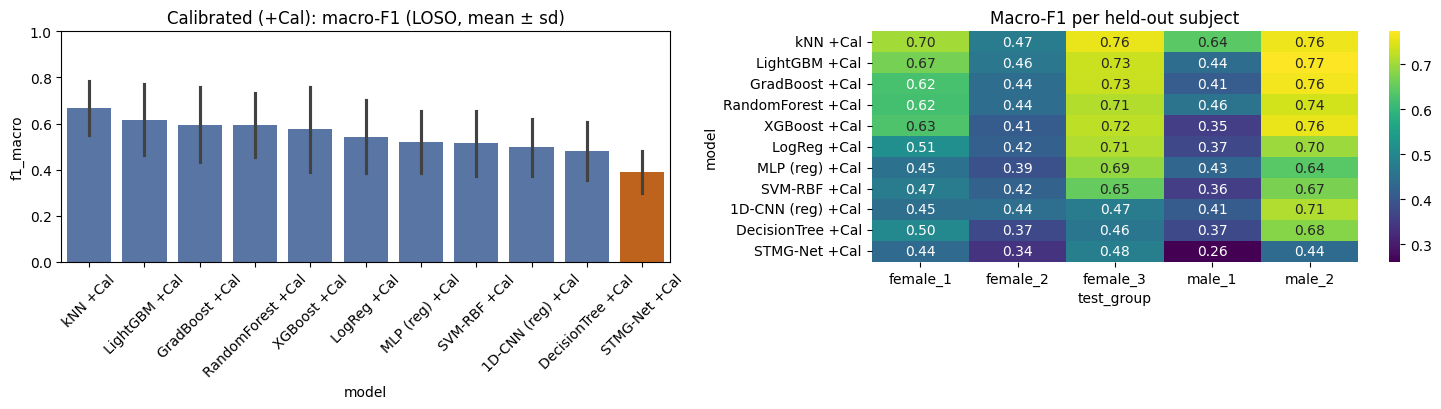

In [34]:
# ============  calibrated (+Cal): GNN vs calibrated baselines ============
d = pd.DataFrame(ROWS)
GNN = "STMG-Net +Cal"
CAL_NAMES = [m for m in d.model.unique() if m.endswith("+Cal") and not m.startswith("STMG")]
ALL_CAL = CAL_NAMES + [GNN] + [m for m in ["STMG-Net (no edges) +Cal"] if m in set(d.model)]

tab, num = summarize(ROWS, ALL_CAL)
display(tab.rename(columns={"fit_s": "train time (s/fold)", "pred_s": "infer time (s/fold)"}))

BEST_CAL = num.loc[CAL_NAMES, "f1_macro"].idxmax()
best_f1 = num.loc[BEST_CAL, "f1_macro"]
cmp = pd.DataFrame({"macro-F1": num["f1_macro"], "Δ vs best cal. baseline": num["f1_macro"] - best_f1,
                    "acc": num["acc"], "MCC": num["mcc"]}).round(3)
print(f"Best calibrated baseline: {BEST_CAL}")
display(cmp)

# ---- per-subject: STMG-Net +Cal vs best calibrated baseline ----
per = d.pivot_table(index="model", columns="test_group", values="f1_macro")
delta = (per.loc[GNN] - per.loc[BEST_CAL]).rename(f"{GNN} − {BEST_CAL}")
print(f"\nPer-subject macro-F1 difference vs {BEST_CAL} (positive = GNN better):")
display(delta.round(3).to_frame().T)
print(f"GNN beats {BEST_CAL} on {(delta > 0).sum()} / {len(delta)} held-out subjects; "
      f"mean Δ macro-F1 = {delta.mean():+.3f}.  (n = {len(delta)} subjects -> indicative, not statistically conclusive.)")

# ---- plots ----
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
dd = d[d.model.isin(ALL_CAL)]
sns.barplot(data=dd, x="model", y="f1_macro", order=num.index, errorbar="sd", ax=ax[0],
            palette=["#d95f02" if m.startswith("STMG") else "#4c72b0" for m in num.index])
ax[0].tick_params(axis="x", rotation=45); ax[0].set_ylim(0, 1)
ax[0].set_title("Calibrated (+Cal): macro-F1 (LOSO, mean ± sd)")
sns.heatmap(per.loc[num.index], annot=True, fmt=".2f", cmap="viridis", ax=ax[1])
ax[1].set_title("Macro-F1 per held-out subject")
plt.tight_layout(); plt.show()

In [35]:
# ============  ADAPT — 9 baselines + STMG-Net, each adapted with X_Cal (all tuning uses ONLY calibration trials) ============
# Needs the earlier cells: D, FOLDS, znorm_by_group, record, reset, get_scores, to_t, predict_logits, prep_cnn, prep_gnn,
#                          CNN1Dreg, STMGNet, xgb, lgb, EPS, FS, SEED, N_CLS, DEV
from scipy.stats import skew, kurtosis
from sklearn.preprocessing import StandardScaler, FunctionTransformer

# ---------- 1) richer features (22 -> 64) ----------
BANDS = [(5, 20), (20, 40), (40, 60), (60, 85), (85, 115), (115, 150), (150, 200), (200, 251)]
def extra_feats(W):
    W = W.astype(np.float64); n, _, T = W.shape
    P = np.abs(np.fft.rfft(W, axis=-1)) ** 2; f = np.fft.rfftfreq(T, 1.0 / FS)
    tot = np.log(P.sum(-1) + EPS)
    bp  = np.stack([np.log(P[..., (f >= lo) & (f < hi)].sum(-1) + EPS) - tot for lo, hi in BANDS], -1)
    r   = np.stack([(W[..., :T - l] * W[..., l:]).sum(-1) for l in range(5)], -1) / T
    R   = r[..., np.abs(np.arange(4)[:, None] - np.arange(4)[None, :])] + 1e-6 * r[..., :1, None] * np.eye(4)
    ar  = np.linalg.solve(R, r[..., 1:5, None])[..., 0]
    dx, ddx = np.diff(W, axis=-1), np.diff(W, n=2, axis=-1)
    mob = np.sqrt(dx.var(-1) / (W.var(-1) + EPS)); mob2 = np.sqrt(ddx.var(-1) / (dx.var(-1) + EPS))
    hj  = np.stack([np.log(mob + EPS), np.log(mob2 / (mob + EPS) + EPS)], -1)
    sk, ku, mx = skew(W, axis=-1), kurtosis(W, axis=-1), np.log(np.abs(W).max(-1) + EPS)
    per_ch = np.concatenate([bp, ar, hj, sk[..., None], ku[..., None], mx[..., None]], -1)
    return np.concatenate([per_ch.reshape(n, -1), bp[:, 0] - bp[:, 1]], 1)

D["F2"] = np.concatenate([D["F"], np.concatenate([extra_feats(D["W"][i:i + 5000]) for i in range(0, len(D["W"]), 5000)])], 1)
Z_TAB2  = [znorm_by_group(D["F2"], f, axes=(0,)) for f in FOLDS]
def clip6(x): return np.clip(x, -6, 6)
def make_prep2(): return [("imp", SimpleImputer(strategy="median")), ("vt", VarianceThreshold(1e-8)), ("sc", StandardScaler()), ("clip", FunctionTransformer(clip6))]
print("features:", D["F"].shape[1], "->", D["F2"].shape[1])

_XF = {}
def get_X(k):                                    # preprocessed tabular features of fold k (fit on TRAIN subjects only)
    if k not in _XF:
        tr = FOLDS[k]["idx_tr"]
        _XF[k] = Pipeline(make_prep2()).fit(Z_TAB2[k][tr], D["y"][tr]).transform(Z_TAB2[k]).astype(np.float32)
    return _XF[k]

# ---------- 2) split X_Cal by TRIAL (never by window) for tuning / early stopping ----------
def cal_trial_split(fold, n_splits):
    rng = np.random.RandomState(SEED + 100 + fold["k"]); cal = fold["idx_cal"]; trials, ycal = D["trial"][cal], D["y"][cal]; assign = {}
    for c in range(N_CLS):
        t = np.unique(trials[ycal == c]); rng.shuffle(t)
        for j, tt in enumerate(t): assign[tt] = j % n_splits
    a = np.array([assign[t] for t in trials]); return [(cal[a != j], cal[a == j]) for j in range(n_splits)]

def n_cal_trials_per_class(fold):
    cal = fold["idx_cal"]; return min(len(np.unique(D["trial"][cal][D["y"][cal] == c])) for c in range(N_CLS))

def select_param(fold, X, fit_pred, grid, n_splits=3):
    y, tr = D["y"], fold["idx_tr"]; splits = cal_trial_split(fold, min(n_splits, n_cal_trials_per_class(fold))); best = (-1, None)
    for p in grid:
        acc = np.mean([(fit_pred(X, y, tr, cf, ev, **p).argmax(1) == y[ev]).mean() for cf, ev in splits])
        if acc > best[0] + 1e-9: best = (acc, p)
    return best[1]

# ---------- 3) classical baselines (train subjects + up-weighted X_Cal) ----------
def fit_sk(make, replicate, X, y, tr, cal, w, **hp):
    if replicate:                                # kNN has no sample_weight -> copy the calibration windows w times
        idx = np.r_[tr, np.repeat(cal, w)]; return make(**hp).fit(X[idx], y[idx])
    idx = np.r_[tr, cal]; sw = np.r_[np.ones(len(tr)), np.full(len(cal), float(w))]
    return make(**hp).fit(X[idx], y[idx], sample_weight=sw)

def run_sk_adapt(name, make, grid, replicate=False):
    reset(name); y = D["y"]
    def fp(X, y_, tr, cf, ev, **p): return get_scores(fit_sk(make, replicate, X, y_, tr, cf, **p), X[ev])
    for k, fold in enumerate(FOLDS):
        X, tr, cal, te = get_X(k), fold["idx_tr"], fold["idx_cal"], fold["idx_te"]
        assert set(D["trial"][cal]).isdisjoint(set(D["trial"][te]))
        t0 = time.time(); p = select_param(fold, X, fp, grid); m = fit_sk(make, replicate, X, y, tr, cal, **p); t_fit = time.time() - t0
        t0 = time.time(); S = get_scores(m, X[te]); t_pred = time.time() - t0
        trs = np.random.RandomState(SEED).choice(tr, min(4000, len(tr)), replace=False)
        record(name, fold, y[te], m.predict(X[te]), S, y[trs], m.predict(X[trs]), t_fit, t_pred)

WG = [dict(w=w) for w in (2, 8, 24)]
SK_ADAPT = {
 "LogReg +Adapt":       (lambda **h: LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced"), WG, False),
 "SVM-RBF +Adapt":      (lambda **h: SVC(kernel="rbf", C=0.5, gamma=0.02, class_weight="balanced"), WG, False),
 "kNN +Adapt":          (lambda **h: KNeighborsClassifier(n_neighbors=h["k"], n_jobs=-1), [dict(k=k, w=w) for k in (15, 31, 61, 101) for w in (1, 3, 5, 10, 20)], True),
 "DecisionTree +Adapt": (lambda **h: DecisionTreeClassifier(max_depth=6, min_samples_leaf=40, class_weight="balanced", random_state=SEED), WG, False),
 "RandomForest +Adapt": (lambda **h: RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=20, max_features=0.5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED), WG, False),
 "GradBoost +Adapt":    (lambda **h: HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=3, min_samples_leaf=60, l2_regularization=10.0, early_stopping=False, random_state=SEED), WG, False),
}
if xgb is not None:
    SK_ADAPT["XGBoost +Adapt"] = (lambda **h: xgb.XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.05, subsample=0.7, colsample_bytree=0.5, min_child_weight=30, reg_lambda=20.0, tree_method="hist", n_jobs=-1, random_state=SEED, verbosity=0), WG, False)
if lgb is not None:
    SK_ADAPT["LightGBM +Adapt"] = (lambda **h: lgb.LGBMClassifier(n_estimators=150, num_leaves=8, learning_rate=0.05, subsample=0.7, subsample_freq=1, colsample_bytree=0.5, min_child_samples=60, reg_lambda=20.0, n_jobs=-1, random_state=SEED, verbose=-1), WG, False)

for name, (mk, grid, rep) in SK_ADAPT.items():
    print(name); run_sk_adapt(name, mk, grid, rep)

# ---------- 4) deep models: MLP / 1D-CNN / STMG-Net  ->  pre-train on other subjects, fine-tune on X_Cal ----------
class FTMLP(nn.Module):
    def __init__(self, d, h=128, p=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(p), nn.Linear(h, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(p), nn.Linear(h, N_CLS))
    def forward(self, x): return self.net(x)

def prep_mlp2(k, fold):
    X = get_X(k); return lambda idx: (X[idx],)

def train_g(model, opt, get_data, n_epochs, val=None, patience=8, ls=0.05, noise=0.1, bs=256):
    # get_data(ep) -> (tuple_of_input_arrays, labels, sample_weights); val = (tuple_of_input_arrays, labels) or None
    best, best_state, best_ep, bad = np.inf, None, 0, 0
    if val is not None: yv = torch.as_tensor(val[1], dtype=torch.long)
    for ep in range(n_epochs):
        inp, y, w = get_data(ep); T = to_t(inp); yt = torch.as_tensor(y, dtype=torch.long); wt = torch.as_tensor(w, dtype=torch.float32)
        model.train(); perm = torch.randperm(len(yt))
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            if len(b) < 2: continue
            xb = [t[b].to(DEV) for t in T]; xb[0] = xb[0] + noise * torch.randn_like(xb[0])      # noise only on the main input (not on STMG edge weights)
            l = (F.cross_entropy(model(*xb), yt[b].to(DEV), reduction="none", label_smoothing=ls) * wt[b].to(DEV)).sum() / wt[b].sum().to(DEV)
            opt.zero_grad(); l.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
        if val is not None:
            vl = F.cross_entropy(predict_logits(model, val[0]), yv, label_smoothing=ls).item()
            if vl < best - 1e-4: best, best_state, best_ep, bad = vl, copy.deepcopy(model.state_dict()), ep + 1, 0
            else:
                bad += 1
                if bad >= patience: break
    if best_state is not None: model.load_state_dict(best_state)
    return best_ep if val is not None else n_epochs

FT_LR, FT_CAL_W, SRC_REPLAY, FT_EP = 5e-4, 5.0, 3000, 40       # X_Cal windows weigh 5x; + 3000 random source windows per epoch (anti-forgetting)

def run_deep_adapt(name, prep_fn, make_model, pre_ep=60, pre_patience=8, noise=0.1):
    reset(name); y = D["y"]
    for k, fold in enumerate(FOLDS):
        t0 = time.time(); get = prep_fn(k, fold); tr, cal, te = fold["idx_tr"], fold["idx_cal"], fold["idx_te"]
        assert set(D["trial"][cal]).isdisjoint(set(D["trial"][te]))
        va = tr[D["grp"][tr] == fold["val_g"]]; src = tr[D["grp"][tr] != fold["val_g"]]
        torch.manual_seed(SEED + k); rng = np.random.RandomState(SEED + k)
        model = make_model(get(src[:4])).to(DEV)
        # (a) pre-train on the other subjects (early stopping on one held-out TRAIN subject)
        opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-2)
        train_g(model, opt, lambda ep: (get(src), y[src], np.ones(len(src))), pre_ep, (get(va), y[va]), patience=pre_patience, noise=noise)
        state0 = copy.deepcopy(model.state_dict())
        def ft_data(idx):
            def g(ep):
                s = rng.choice(src, min(SRC_REPLAY, len(src)), replace=False); ii = np.r_[idx, s]
                return get(ii), y[ii], np.r_[np.full(len(idx), FT_CAL_W), np.ones(len(s))]
            return g
        new_opt = lambda: torch.optim.AdamW(model.parameters(), lr=FT_LR, weight_decay=1e-2)
        # (b) fine-tune with 1 calibration TRIAL/class held out -> best #epochs  (never touches X_Test)
        cal_fit, cal_val = cal_trial_split(fold, n_cal_trials_per_class(fold))[0]
        model.load_state_dict(state0)
        ep_best = train_g(model, new_opt(), ft_data(cal_fit), FT_EP, (get(cal_val), y[cal_val]), patience=10, noise=0.05)
        # (c) re-fit from the pre-trained weights on ALL of X_Cal for that many epochs
        model.load_state_dict(state0)
        train_g(model, new_opt(), ft_data(cal), max(ep_best, 3), None, noise=0.05)
        t_fit = time.time() - t0
        t0 = time.time(); S = F.softmax(predict_logits(model, get(te)), 1).numpy(); t_pred = time.time() - t0
        trs = np.random.RandomState(SEED).choice(tr, min(4000, len(tr)), replace=False)
        record(name, fold, y[te], S.argmax(1), S, y[trs], predict_logits(model, get(trs)).argmax(1).numpy(), t_fit, t_pred, ep_best)
    print("  params:", sum(p.numel() for p in model.parameters()))

print("MLP +Adapt");       run_deep_adapt("MLP +Adapt",       prep_mlp2, lambda inp: FTMLP(inp[0].shape[1]), pre_ep=60, noise=0.1)
print("1D-CNN +Adapt");    run_deep_adapt("1D-CNN +Adapt",    prep_cnn,  lambda inp: CNN1Dreg(),             pre_ep=30, pre_patience=5, noise=0.05)
print("STMG-Net +Adapt");  run_deep_adapt("STMG-Net +Adapt",  prep_gnn,  lambda inp: STMGNet(),              pre_ep=60, noise=0.05)

# ---------- 5) summary ----------
ADAPT_MODELS = list(SK_ADAPT) + ["MLP +Adapt", "1D-CNN +Adapt", "STMG-Net +Adapt"]
d = pd.DataFrame(ROWS); d = d[d.model.isin(ADAPT_MODELS)]
display(d.groupby("model")[["acc", "f1_macro", "mcc", "auc_ovr", "train_f1", "fit_s"]].mean().loc[ADAPT_MODELS].round(3).sort_values("f1_macro", ascending=False))

features: 22 -> 64
LogReg +Adapt
  [LogReg +Adapt     ] test=female_1   acc=0.813 f1=0.813 | train_f1=0.763 | fit=  46.4s
  [LogReg +Adapt     ] test=female_2   acc=0.767 f1=0.765 | train_f1=0.762 | fit=  48.7s
  [LogReg +Adapt     ] test=female_3   acc=0.848 f1=0.849 | train_f1=0.762 | fit=  45.1s
  [LogReg +Adapt     ] test=male_1     acc=0.836 f1=0.834 | train_f1=0.764 | fit=  45.9s
  [LogReg +Adapt     ] test=male_2     acc=0.942 f1=0.942 | train_f1=0.743 | fit=  39.4s
SVM-RBF +Adapt
  [SVM-RBF +Adapt    ] test=female_1   acc=0.807 f1=0.807 | train_f1=0.942 | fit=  61.4s
  [SVM-RBF +Adapt    ] test=female_2   acc=0.766 f1=0.765 | train_f1=0.944 | fit=  55.2s
  [SVM-RBF +Adapt    ] test=female_3   acc=0.854 f1=0.855 | train_f1=0.942 | fit=  64.3s
  [SVM-RBF +Adapt    ] test=male_1     acc=0.830 f1=0.829 | train_f1=0.936 | fit=  63.0s
  [SVM-RBF +Adapt    ] test=male_2     acc=0.936 f1=0.936 | train_f1=0.927 | fit=  69.0s
kNN +Adapt
  [kNN +Adapt        ] test=female_1   acc=0.830 f1

,acc,f1_macro,mcc,auc_ovr,train_f1,fit_s
model,,,,,,
MLP +Adapt,0.867,0.866,0.842,0.982,0.746,5.573
LightGBM +Adapt,0.864,0.863,0.838,0.980,0.877,16.620
XGBoost +Adapt,0.863,0.862,0.837,0.979,0.797,23.259
GradBoost +Adapt,0.860,0.860,0.834,0.979,0.873,33.918
kNN +Adapt,0.859,0.858,0.832,0.969,0.829,2.236
LogReg +Adapt,0.841,0.841,0.811,0.976,0.759,45.109
SVM-RBF +Adapt,0.839,0.838,0.808,0.961,0.938,62.560
RandomForest +Adapt,0.834,0.834,0.803,0.975,0.845,481.351
1D-CNN +Adapt,0.806,0.802,0.771,0.961,0.451,8.084


===== ADAPTED (train subjects + labelled X_Cal of the test subject) =====


,f1_macro,acc,bal_acc,mcc,auc_ovr,train_f1,train time (s),gap (train-test F1),Δ F1 vs best base
model,,,,,,,,,
MLP +Adapt,0.866,0.867,0.867,0.842,0.982,0.746,5.573,-0.121,0.000
LightGBM +Adapt,0.863,0.864,0.864,0.838,0.980,0.877,16.620,0.014,-0.003
XGBoost +Adapt,0.862,0.863,0.863,0.837,0.979,0.797,23.259,-0.065,-0.004
GradBoost +Adapt,0.860,0.860,0.860,0.834,0.979,0.873,33.918,0.013,-0.007
kNN +Adapt,0.858,0.859,0.859,0.832,0.969,0.829,2.236,-0.029,-0.008
LogReg +Adapt,0.841,0.841,0.841,0.811,0.976,0.759,45.109,-0.082,-0.026
SVM-RBF +Adapt,0.838,0.839,0.839,0.808,0.961,0.938,62.560,0.100,-0.028
RandomForest +Adapt,0.834,0.834,0.834,0.803,0.975,0.845,481.351,0.011,-0.032
1D-CNN +Adapt,0.802,0.806,0.806,0.771,0.961,0.451,8.084,-0.351,-0.064



macro-F1 per held-out subject:


test_group,female_1,female_2,female_3,male_1,male_2,mean,sd
model,,,,,,,
MLP +Adapt,0.849,0.792,0.879,0.854,0.958,0.866,0.060
LightGBM +Adapt,0.839,0.812,0.877,0.856,0.932,0.863,0.045
XGBoost +Adapt,0.838,0.812,0.879,0.847,0.935,0.862,0.047
GradBoost +Adapt,0.835,0.803,0.872,0.846,0.942,0.860,0.052
kNN +Adapt,0.830,0.760,0.870,0.867,0.964,0.858,0.074
LogReg +Adapt,0.813,0.765,0.849,0.834,0.942,0.841,0.065
SVM-RBF +Adapt,0.807,0.765,0.855,0.829,0.936,0.838,0.064
RandomForest +Adapt,0.825,0.752,0.838,0.820,0.934,0.834,0.065
1D-CNN +Adapt,0.808,0.682,0.792,0.823,0.904,0.802,0.080



Best base model : MLP +Adapt  (macro-F1 0.866)
GNN (STMG-Net +Adapt)     : macro-F1 0.702  -> Δ = -0.165
Per held-out subject Δ macro-F1 (GNN − best base): {'female_1': -0.171, 'female_2': -0.3, 'female_3': -0.116, 'male_1': -0.122, 'male_2': -0.114}
GNN better on 0 / 5 subjects  -> GNN does NOT beat the best base model on average
GNN rank: 11 / 11 by mean macro-F1


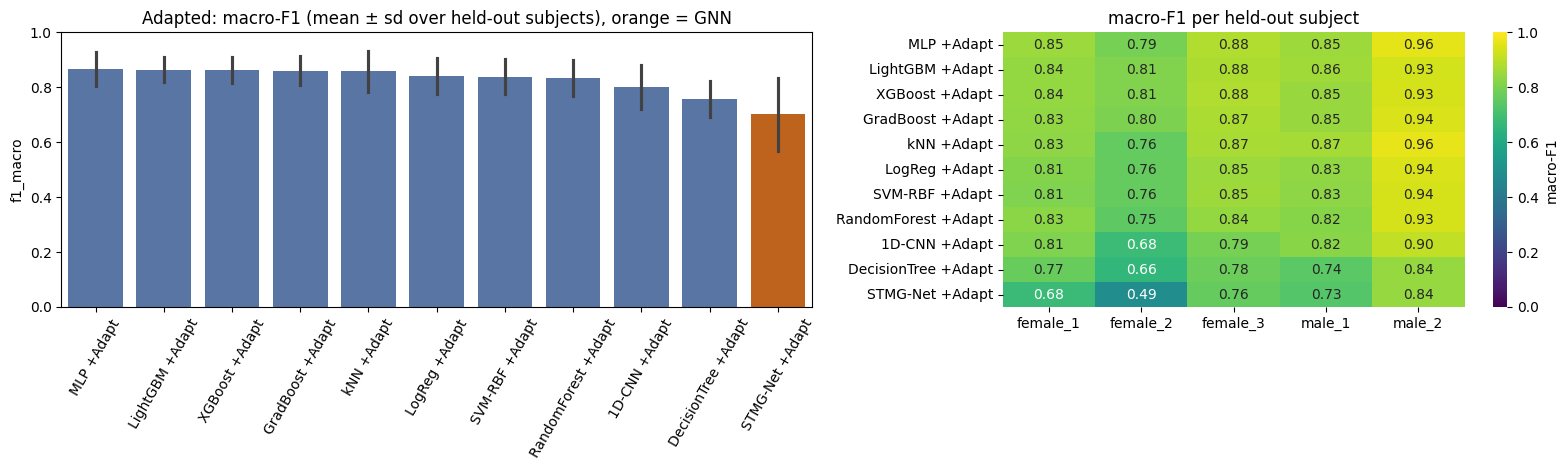

In [36]:
# ============  STMG-Net +Adapt vs the 10 baselines (+Adapt) — only the models from CELL 22 ============
GNN   = "STMG-Net +Adapt"
BASES = [m for m in ["LogReg +Adapt", "SVM-RBF +Adapt", "kNN +Adapt", "DecisionTree +Adapt", "RandomForest +Adapt",
                     "GradBoost +Adapt", "XGBoost +Adapt", "LightGBM +Adapt", "MLP +Adapt", "1D-CNN +Adapt"]
         if m in {r["model"] for r in ROWS}]

d = pd.DataFrame(ROWS)
d = d[d.model.isin(BASES + [GNN])]

# 1) remove duplicate rows (same model + same held-out subject) -> keep the latest run
d = d.drop_duplicates(subset=["model", "test_group"], keep="last")

# 2) completeness check: every model must have a result for ALL held-out subjects
n_sub = d["test_group"].nunique()
cnt = d.groupby("model")["test_group"].nunique()
incomplete = cnt[cnt < n_sub].index.tolist()
if incomplete:
    print(f"⚠ WARNING: incomplete models (fewer than {n_sub} subjects) were EXCLUDED: {incomplete}")
    print("  -> re-run their +Adapt cell (CELL 22) so all folds are added to ROWS, then re-run this cell.\n")
    d = d[~d.model.isin(incomplete)]
    BASES = [m for m in BASES if m not in incomplete]
assert GNN in set(d.model), "STMG-Net +Adapt results are missing/incomplete in ROWS"

METRICS = ["f1_macro", "acc", "bal_acc", "mcc", "auc_ovr", "train_f1", "fit_s"]

g = d.groupby("model")[METRICS].mean()
g["gap (train-test F1)"] = g.train_f1 - g.f1_macro
best = g.loc[BASES, "f1_macro"].idxmax()
g["Δ F1 vs best base"] = g.f1_macro - g.loc[best, "f1_macro"]
g = g.sort_values("f1_macro", ascending=False)
print("===== ADAPTED (train subjects + labelled X_Cal of the test subject) =====")
display(g.rename(columns={"fit_s": "train time (s)"}).round(3))

# per-subject macro-F1 of every model
per_sub = d.pivot_table(index="model", columns="test_group", values="f1_macro").loc[g.index]
per_all = per_sub.copy()
per_all["mean"] = per_sub.mean(axis=1)
per_all["sd"] = d.groupby("model")["f1_macro"].std().loc[g.index]
print("\nmacro-F1 per held-out subject:"); display(per_all.round(3))

diff = per_sub.loc[GNN] - per_sub.loc[best]
print(f"\nBest base model : {best}  (macro-F1 {g.loc[best,'f1_macro']:.3f})")
print(f"GNN ({GNN})     : macro-F1 {g.loc[GNN,'f1_macro']:.3f}  -> Δ = {g.loc[GNN,'f1_macro']-g.loc[best,'f1_macro']:+.3f}")
print("Per held-out subject Δ macro-F1 (GNN − best base):", diff.round(3).to_dict())
print(f"GNN better on {(diff > 0).sum()} / {len(diff)} subjects  ->",
      "GNN WINS on average" if diff.mean() > 0 else "GNN does NOT beat the best base model on average")
print(f"GNN rank: {list(g.index).index(GNN) + 1} / {len(g)} by mean macro-F1")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw=dict(width_ratios=[1.3, 1]))
sns.barplot(data=d, x="model", y="f1_macro", order=g.index, errorbar="sd", ax=axes[0], hue="model", legend=False,
            palette={m: ("#d95f02" if m == GNN else "#4c72b0") for m in g.index})
axes[0].set_title("Adapted: macro-F1 (mean ± sd over held-out subjects), orange = GNN")
axes[0].tick_params(axis="x", rotation=60); axes[0].set_ylim(0, 1); axes[0].set_xlabel("")
sns.heatmap(per_sub, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=axes[1], cbar_kws=dict(label="macro-F1"))
axes[1].set_title("macro-F1 per held-out subject"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

In [38]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    f1_score,
    roc_auc_score
)

print("Available metric keys:")
print(ROWS[0].keys())

Available metric keys:
dict_keys(['acc', 'bal_acc', 'prec_macro', 'rec_macro', 'f1_macro', 'f1_weighted', 'mcc', 'kappa', 'auc_ovr', 'model', 'test_group', 'train_f1', 'fit_s', 'pred_s', 'epochs'])


===== MODEL PERFORMANCE COMPARISON =====


,f1_macro,acc,bal_acc,mcc,auc_ovr,train_f1,training time (s),gap (train-test F1),Δ F1 vs best base
model,,,,,,,,,
MLP +Adapt,0.866,0.867,0.867,0.842,0.982,0.746,5.573,-0.121,0.000
LightGBM +Adapt,0.863,0.864,0.864,0.838,0.980,0.877,16.620,0.014,-0.003
XGBoost +Adapt,0.862,0.863,0.863,0.837,0.979,0.797,23.259,-0.065,-0.004
GradBoost +Adapt,0.860,0.860,0.860,0.834,0.979,0.873,33.918,0.013,-0.007
kNN +Adapt,0.858,0.859,0.859,0.832,0.969,0.829,2.236,-0.029,-0.008
LogReg +Adapt,0.841,0.841,0.841,0.811,0.976,0.759,45.109,-0.082,-0.026
SVM-RBF +Adapt,0.838,0.839,0.839,0.808,0.961,0.938,62.560,0.100,-0.028
RandomForest +Adapt,0.834,0.834,0.834,0.803,0.975,0.845,481.351,0.011,-0.032
1D-CNN +Adapt,0.802,0.806,0.806,0.771,0.961,0.451,8.084,-0.351,-0.064



===== MACRO-F1 PER HELD-OUT SUBJECT =====


test_group,female_1,female_2,female_3,male_1,male_2,mean,sd
model,,,,,,,
MLP +Adapt,0.849,0.792,0.879,0.854,0.958,0.866,0.060
LightGBM +Adapt,0.839,0.812,0.877,0.856,0.932,0.863,0.045
XGBoost +Adapt,0.838,0.812,0.879,0.847,0.935,0.862,0.047
GradBoost +Adapt,0.835,0.803,0.872,0.846,0.942,0.860,0.052
kNN +Adapt,0.830,0.760,0.870,0.867,0.964,0.858,0.074
LogReg +Adapt,0.813,0.765,0.849,0.834,0.942,0.841,0.065
SVM-RBF +Adapt,0.807,0.765,0.855,0.829,0.936,0.838,0.064
RandomForest +Adapt,0.825,0.752,0.838,0.820,0.934,0.834,0.065
1D-CNN +Adapt,0.808,0.682,0.792,0.823,0.904,0.802,0.080



Best base model: MLP +Adapt
Best base Macro-F1: 0.866
STMG-Net Macro-F1: 0.244
Δ F1 vs best baseline: -0.623

Per-subject Δ Macro-F1 (STMG-Net − best baseline): {'female_1': -0.64, 'female_2': -0.599, 'female_3': -0.557, 'male_1': -0.667, 'male_2': -0.652}

STMG-Net better on 0/5 subjects
Result: STMG-Net DOES NOT beat the best baseline on average
STMG-Net rank: 11/11


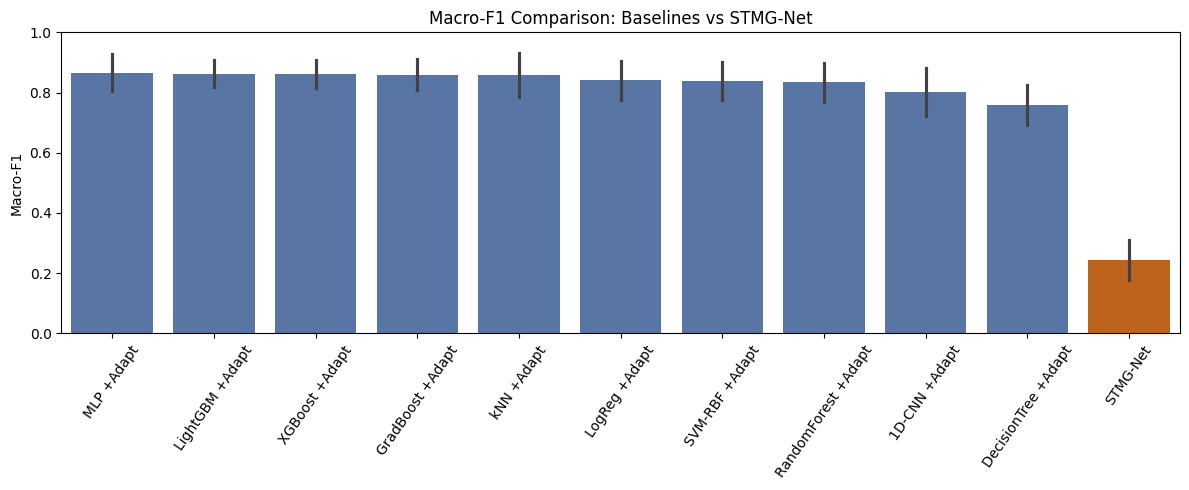


Results saved successfully.


In [39]:

# =======STMG-Net vs 9 Baselines (NO HEATMAP) ============

GNN = "STMG-Net"

BASES = [
    m for m in [
        "LogReg +Adapt",
        "SVM-RBF +Adapt",
        "kNN +Adapt",
        "DecisionTree +Adapt",
        "RandomForest +Adapt",
        "GradBoost +Adapt",
        "XGBoost +Adapt",
        "LightGBM +Adapt",
        "MLP +Adapt",
        "1D-CNN +Adapt"
    ]
    if m in {r["model"] for r in ROWS}
]

d = pd.DataFrame(ROWS)
d = d[d["model"].isin(BASES + [GNN])].copy()

if GNN not in d["model"].values:
    raise ValueError("STMG-Net results not found in ROWS.")

if not BASES:
    raise ValueError("No baseline models found in ROWS.")

# Metrics
METRICS = [
    "f1_macro",
    "acc",
    "bal_acc",
    "mcc",
    "auc_ovr",
    "train_f1",
    "fit_s"
]

missing = [m for m in METRICS if m not in d.columns]
if missing:
    raise ValueError(f"Missing metrics: {missing}")

# ------------------------------------------------------------
# 1. AVERAGE PERFORMANCE
# ------------------------------------------------------------

g = d.groupby("model")[METRICS].mean()

g["gap (train-test F1)"] = (
    g["train_f1"] - g["f1_macro"]
)

best = g.loc[BASES, "f1_macro"].idxmax()

g["Δ F1 vs best base"] = (
    g["f1_macro"] - g.loc[best, "f1_macro"]
)

g = g.sort_values("f1_macro", ascending=False)

print("===== MODEL PERFORMANCE COMPARISON =====")

display(
    g.rename(columns={
        "fit_s": "training time (s)"
    }).round(3)
)

# ------------------------------------------------------------
# 2. PER-SUBJECT MACRO-F1
# ------------------------------------------------------------

per_all = d.pivot_table(
    index="model",
    columns="test_group",
    values="f1_macro",
    aggfunc="mean"
).loc[g.index]

per_all["mean"] = per_all.mean(axis=1)

per_all["sd"] = (
    d.groupby("model")["f1_macro"]
    .std()
    .reindex(per_all.index)
)

print("\n===== MACRO-F1 PER HELD-OUT SUBJECT =====")
display(per_all.round(3))

# ------------------------------------------------------------
# 3. PROPOSED MODEL vs BEST BASELINE
# ------------------------------------------------------------

subject_cols = [
    c for c in per_all.columns
    if c not in ["mean", "sd"]
]

diff = (
    per_all.loc[GNN, subject_cols]
    - per_all.loc[best, subject_cols]
)

print(f"\nBest base model: {best}")
print(f"Best base Macro-F1: {g.loc[best, 'f1_macro']:.3f}")

print(
    f"STMG-Net Macro-F1: "
    f"{g.loc[GNN, 'f1_macro']:.3f}"
)

print(
    f"Δ F1 vs best baseline: "
    f"{g.loc[GNN, 'f1_macro'] - g.loc[best, 'f1_macro']:+.3f}"
)

print(
    "\nPer-subject Δ Macro-F1 "
    "(STMG-Net − best baseline):",
    diff.round(3).to_dict()
)

wins = (diff > 0).sum()

print(
    f"\nSTMG-Net better on {wins}/{len(subject_cols)} subjects"
)

print(
    "Result:",
    "STMG-Net WINS on average"
    if diff.mean() > 0
    else "STMG-Net DOES NOT beat the best baseline on average"
)

print(
    f"STMG-Net rank: "
    f"{list(g.index).index(GNN) + 1}/{len(g)}"
)

# ------------------------------------------------------------
# 4. BAR CHART ONLY
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(
    data=d,
    x="model",
    y="f1_macro",
    order=g.index,
    errorbar="sd",
    ax=ax,
    hue="model",
    legend=False,
    palette={
        m: ("#d95f02" if m == GNN else "#4c72b0")
        for m in g.index
    }
)

ax.set_title(
    "Macro-F1 Comparison: Baselines vs STMG-Net"
)

ax.set_ylabel("Macro-F1")
ax.set_xlabel("")
ax.set_ylim(0, 1)

ax.tick_params(
    axis="x",
    rotation=55
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------------------

g.to_csv("STMGNet_Model_Comparison.csv")
per_all.to_csv("STMGNet_Subjectwise_Comparison.csv")

print("\nResults saved successfully.")


In [37]:

y = D["y"]; ok = True
def chk(label, cond, extra=""):
    global ok; ok &= bool(cond); print(f"  [{'PASS' if cond else 'FAIL'}] {label} {extra}")

print("A) split integrity (every fold)")
for k, fold in enumerate(FOLDS):
    tr, cal, te = fold["idx_tr"], fold["idx_cal"], fold["idx_te"]
    chk(f"fold {k} ({fold['test_g']}): subject  train∩test = ∅ and train∩cal = ∅", not (set(D["grp"][tr]) & set(D["grp"][te])) and not (set(D["grp"][tr]) & set(D["grp"][cal])))
    chk(f"fold {k}: trial    train∩test = ∅, cal∩test = ∅, train∩cal = ∅", not (set(D["trial"][tr]) & set(D["trial"][te])) and not (set(D["trial"][cal]) & set(D["trial"][te])) and not (set(D["trial"][tr]) & set(D["trial"][cal])))
    chk(f"fold {k}: window indices disjoint & cover all data", len(set(tr) | set(cal) | set(te)) == len(y) == len(tr) + len(cal) + len(te))
    chk(f"fold {k}: early-stopping subject is a TRAIN subject (≠ test subject)", fold["val_g"] != fold["test_g"] and fold["val_g"] in set(D["grp"][tr]))

print("B) tuning / early-stopping splits use ONLY X_Cal and never X_Test")
for k, fold in enumerate(FOLDS):
    sp = cal_trial_split(fold, min(3, n_cal_trials_per_class(fold))); cal, te = set(fold["idx_cal"]), set(fold["idx_te"])
    inside = all(set(a) <= cal and set(b) <= cal and not (te & (set(a) | set(b))) for a, b in sp)
    trial_disj = all(not (set(D["trial"][a]) & set(D["trial"][b])) for a, b in sp)
    chk(f"fold {k}: cal_fit/cal_val ⊂ X_Cal, no X_Test window, split by TRIAL (no trial in both)", inside and trial_disj)

print("C) per-subject Z-norm: test-subject statistics come from X_Cal only")
for k, fold in enumerate(FOLDS):
    Z, cal, te = Z_TAB2[k], fold["idx_cal"], fold["idx_te"]
    chk(f"fold {k}: Z[X_Cal] has mean≈0, std≈1 per feature (⇒ stats = X_Cal)", np.abs(Z[cal].mean(0)).max() < 1e-4 and np.allclose(Z[cal].std(0)[Z[cal].std(0) > 1e-6], 1, atol=1e-3),
        f"| Z[X_Test] mean|.|max = {np.abs(Z[te].mean(0)).max():.2f} (≠0 is expected)")
    Zp = znorm_by_group(np.where(np.isin(np.arange(len(y)), te)[:, None], D["F2"] + 1e3, D["F2"]), fold, axes=(0,))      # perturb X_Test features massively
    chk(f"fold {k}: changing X_Test values does NOT change any normalised X_Cal/train value", np.allclose(Zp[np.r_[fold['idx_tr'], cal]], Z[np.r_[fold['idx_tr'], cal]]))

print("D) preprocessing (imputer / variance filter / scaler) is fitted on TRAIN subjects only")
for k, fold in enumerate(FOLDS):
    tr = fold["idx_tr"]; pp = Pipeline(make_prep2()).fit(Z_TAB2[k][tr], y[tr])
    chk(f"fold {k}: scaler mean == mean of training windows", np.allclose(pp.named_steps["sc"].mean_, pp.named_steps["vt"].transform(pp.named_steps["imp"].transform(Z_TAB2[k][tr])).mean(0), atol=1e-5))

print("E) sanity: permuted labels must give ≈ chance (fold 0)")
fold = FOLDS[0]; tr, cal, te = fold["idx_tr"], fold["idx_cal"], fold["idx_te"]; X0 = get_X(0)
yp = y.copy(); rs = np.random.RandomState(0); yp[tr] = rs.permutation(y[tr]); yp[cal] = rs.permutation(y[cal])            # shuffle ALL labels the model may see
for nm, (mk, _, rep) in [(n, SK_ADAPT[n]) for n in ("LogReg +Adapt", "kNN +Adapt", "RandomForest +Adapt")]:
    m = fit_sk(mk, rep, X0, yp, tr, cal, 5, k=31); acc = accuracy_score(y[te], m.predict(X0[te]))
    chk(f"{nm:22s} permuted-label test acc = {acc:.3f} (chance {1/N_CLS:.3f})", acc < 1 / N_CLS + 0.10)

print("F) random-window split vs subject-independent (LOSO) — shows why only LOSO is reported")
rf = lambda: Pipeline(make_prep2() + [("clf", RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=SEED))])
rand_acc = cross_val_score(rf(), Z_TAB2[0], y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="accuracy", n_jobs=1).mean()
loso_acc = cross_val_score(rf(), Z_TAB2[0], y, cv=GroupKFold(len(GROUPS)), groups=D["grp"], scoring="accuracy", n_jobs=1).mean()
print(f"  RandomForest: random-window-split acc = {rand_acc:.3f}  vs  LOSO acc = {loso_acc:.3f}  -> random split is over-optimistic (windows of one trial are near-duplicates)")

print("\nOVERALL:", "ALL CHECKS PASSED — no leakage detected" if ok else "SOME CHECKS FAILED — inspect above")

A) split integrity (every fold)
  [PASS] fold 0 (female_1): subject  train∩test = ∅ and train∩cal = ∅ 
  [PASS] fold 0: trial    train∩test = ∅, cal∩test = ∅, train∩cal = ∅ 
  [PASS] fold 0: window indices disjoint & cover all data 
  [PASS] fold 0: early-stopping subject is a TRAIN subject (≠ test subject) 
  [PASS] fold 1 (female_2): subject  train∩test = ∅ and train∩cal = ∅ 
  [PASS] fold 1: trial    train∩test = ∅, cal∩test = ∅, train∩cal = ∅ 
  [PASS] fold 1: window indices disjoint & cover all data 
  [PASS] fold 1: early-stopping subject is a TRAIN subject (≠ test subject) 
  [PASS] fold 2 (female_3): subject  train∩test = ∅ and train∩cal = ∅ 
  [PASS] fold 2: trial    train∩test = ∅, cal∩test = ∅, train∩cal = ∅ 
  [PASS] fold 2: window indices disjoint & cover all data 
  [PASS] fold 2: early-stopping subject is a TRAIN subject (≠ test subject) 
  [PASS] fold 3 (male_1): subject  train∩test = ∅ and train∩cal = ∅ 
  [PASS] fold 3: trial    train∩test = ∅, cal∩test = ∅, train∩cal